# Projet Data ES

Lien du github : https://github.com/juleslapeuf/projet-data-es.git


In [1]:
# Bibliothèques standard
import time
import math

# Analyse et visualisation
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Données géographiques et web
import geopandas as gpd
import requests
from cartiflette import carti_download
from io import BytesIO
from matplotlib.lines import Line2D

# Fonctions du projet
from fonctions import *

In [2]:
import matplotlib.ticker as ticker
from matplotlib.patches import ConnectionPatch

# I/ Récupération

## A. **Récupération des données : prise en main de l'API**

<div style="text-align: justify;">
<div style="text-align: justify; line-height: 1.8;">
Nous utiliserons la base de données Data ES qui recense près de 330 000 infrastructures sportives en France. Ces données sont mises à disposition par le ministère chargé des sports afin *"d’aider à une meilleure perception des inégali­tés ter­ri­to­ria­les dans leur répar­ti­tion"*, perspective dans laquelle s'inscrit notre travail. Il faut dire que le recensement des équipements sportifs est obligatoire et les fiches sont créées par les propriétaires des équipements ou par des utilisateurs.

Les données que nous allons utiliser sont accessibles par une API qui nous permet de n'accéder qu'à quelques valeurs choisies en évitant de tout télécharger chaque fois. Deux modes d'accès sont permis, l'un limite à 100 éléments livrant directement un dataframe, un autre sans limite donne le lien de téléchargement d'un .csv. Le lien est construit sur l'interface du site avec une syntaxe proche du SQL accessible ici : https://equipements.sports.gouv.fr/explore/dataset/data-es/api/?q.

Les fonctions qui permettent d'obtenir les dataframes par ces deux méthodes sont importées et visibles depuis fonctions.py.

<div style="text-align: justify;">
<div style="text-align: justify; line-height: 1.8;">
Pour travailler sur des données nettoyées et éviter de refaire le travail de nettoyage à chaque appel, il nous faut garder en mémoire notre traitement. Cependant, pour ne pas avoir un appel trop lourd, nous nous limiterons à n'appeler qu'une partie des 117 caractéristiques d'équipements sportifs disponibles.
</div>
</div>

<div style="text-align: justify;">
<div style="text-align: justify; line-height: 1.8;">
Nous allons donc procéder au traitement sur le jeu réduit de paramètres (17/117 disponibles):

In [3]:
colonnes = [
    "inst_numero",
    "inst_nom",
    "dep_nom",
    #"dep_code_filled",
    "new_code",
    "new_name",
    #"epci_nom",
    #"inst_hs_bool",
    #"inst_acc_handi_bool",
    #"inst_acc_handi_type",
    #"inst_trans_type",
    "equip_numero",
    "equip_nom",
    "equip_type_code",
    "equip_type_name",
    "equip_type_famille",
    "equip_x",
    "equip_y",
    "equip_gest_type",
    #"equip_ouv_public_bool",
    "equip_acc_libre",
    #"equip_eclair",
    #"equip_douche",
    #"equip_sanit",
    #"equip_pmr_aire",
    #"equip_pmr_douche",
    #"equip_pmr_sanit",
    "equip_service_date",
    "equip_service_periode",
    #"equip_travaux_date",
    #"equip_travaux_type",
    #"equip_energie",
    #"equip_nature",
    #"equip_prop_type",
    "dens_lib",
]

In [4]:
#Cette cellule prend environ 1m30 à être exécutée, elle appelle tous les équipements 
# sur les 17 caractéristiques précedemment identifiées.
url = creer_url_api(colonnes)

recensement = call_csv(url)
recensement.head(3)

,inst_numero,inst_nom,dep_nom,new_code,new_name,equip_numero,equip_nom,equip_type_code,equip_type_name,equip_type_famille,equip_x,equip_y,equip_gest_type,equip_acc_libre,equip_service_date,equip_service_periode,dens_lib
0,I2A0010001,Stade municipal d'AFA,Corse-du-Sud,2A001,Afa,E002I2A0010001,Salle des fêtes: culturelle et sportive.,2201,Salles polyvalentes / des fêtes / non spéciali...,Salle non spécialisée,8.798290,41.98762,Commune,False,2007.0,A partir de 2005,Bourgs ruraux
1,I2A0010001,Stade municipal d'AFA,Corse-du-Sud,2A001,Afa,E001I2A0010001,stade municipal d'AFA,2802,Terrain de football,Terrain de grands jeux,8.798784,41.98740,Commune,False,1983.0,NaN,Bourgs ruraux
2,I2A0040001,Ecole primaire les jardins de l'empereur,Corse-du-Sud,2A004,Ajaccio,E001I2A0040001,terrain de basket,2901,Terrain de basket-ball,Terrain extérieur de petits jeux collectifs,8.726578,41.92717,Commune,False,NaN,NaN,Centres urbains intermédiaires


In [5]:
recensement.isna().sum()

inst_numero                   0
inst_nom                     19
dep_nom                     205
new_code                     48
new_name                     19
equip_numero                  0
equip_nom                     0
equip_type_code               0
equip_type_name               0
equip_type_famille            0
equip_x                    1730
equip_y                    1730
equip_gest_type           11190
equip_acc_libre               0
equip_service_date       125054
equip_service_periode     38773
dens_lib                   2611
dtype: int64

## B. **Squelette des données**

<div style="text-align: justify;">
<div style="text-align: justify; line-height: 1.8;">

Les données disponibles sont très propres, et la base est mise à jour très régulièrement, ce qui suggère beaucoup de travail derrière afin de maintenir la qualité du recensement. 

Chaque ligne du jeu de données correspond à un équipement sportif, et cela signifie que dans la même installation et au même lieu géographique, il peut y avoir plusieurs équipements sportifs. Par exemple, dans le cas d'une piscine, il faut déclarer chaque bassin en tant que deux équipements comme on peut le voir pour la piscine de la commune d'Orgnac-l'Aven. On remarque un code de l'installation (inst_numero) et un code pour l'équipement (equip_numero).
</div>
</div>

In [6]:
colonnes_a_afficher = ['inst_numero', 'equip_numero', 'new_name', 'equip_type_famille', "equip_nom"]
print(recensement[recensement['inst_numero'].isin(['I071680005'])][colonnes_a_afficher])

      inst_numero    equip_numero       new_name  equip_type_famille  \
21882  I071680005  E001I071680005  Orgnac-l'Aven  Bassin de natation   
21883  I071680005  E002I071680005  Orgnac-l'Aven  Bassin de natation   

                  equip_nom  
21882  Bassin rectangulaire  
21883           Bassin rond  


# II. Exploration des équipements sportifs en France

## A. **Qui gère les équipements sportifs en France ?**

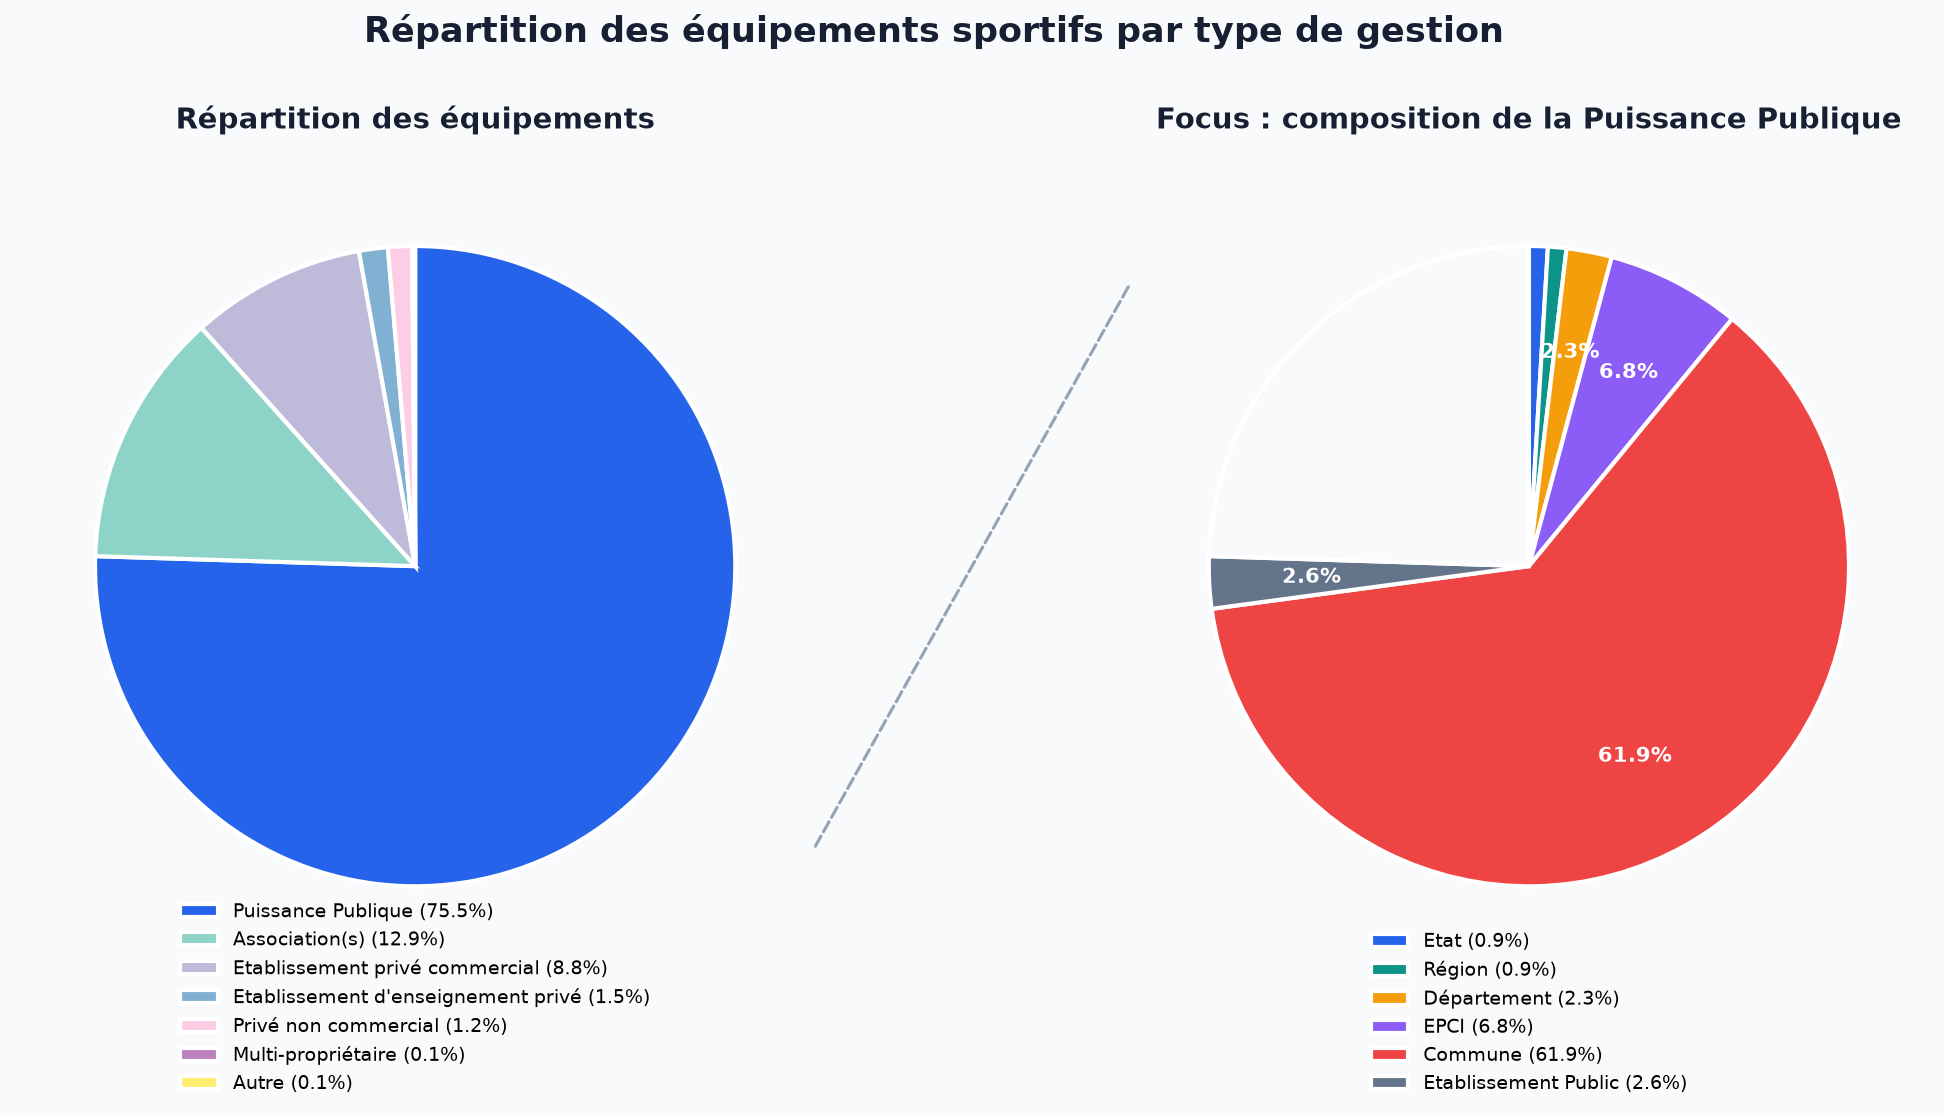

In [7]:
# 1. Définir les modalités de la Puissance Publique
strates_publiques = [
    "Etat",
    "Région",
    "Département",
    "EPCI",
    "Commune",
    "Etablissement Public"
]

# 2. Compter les effectifs
gestion = recensement["equip_gest_type"].value_counts().dropna()

# Regrouper les modalités publiques
effectifs_publics = gestion.reindex(strates_publiques, fill_value=0)
total_public = effectifs_publics.sum()

# Les autres modalités restent distinctes
autres = gestion.drop(index=strates_publiques, errors="ignore")

# Données du camembert principal
labels_principal = ["Puissance Publique"] + autres.index.tolist()
valeurs_principales = [total_public] + autres.tolist()

# Couleurs
couleur_public = "#2563EB"
couleurs_autres = plt.cm.Set3(np.linspace(0, 1, len(autres)))
couleurs_principales = [couleur_public] + list(couleurs_autres)

# Couleurs des strates publiques
palette_strates = {
    "Etat": "#2563EB",
    "Région": "#0D9488",
    "Département": "#F59E0B",
    "EPCI": "#8B5CF6",
    "Commune": "#EF4444",
    "Etablissement Public": "#64748B"
}

# Total général
total_general = sum(valeurs_principales)

# Retirer les strates à zéro pour le graphique détaillé
effectifs_publics = effectifs_publics[effectifs_publics > 0]

# 3. Créer la figure
fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(15, 8),
    dpi=150,
    gridspec_kw={"width_ratios": [1.15, 1]}
)

fig.patch.set_facecolor("#F8FAFC")

# Camembert principal
wedges1, _ = ax1.pie(
    valeurs_principales,
    startangle=90,
    counterclock=False,
    colors=couleurs_principales,
    wedgeprops={"edgecolor": "white", "linewidth": 2}
)

# Récupérer la part Puissance Publique
wedge_public = wedges1[0]

ax1.set_title(
    "Répartition des équipements",
    fontsize=14, fontweight="bold", color="#172033", pad=18
)

# Légende principale avec effectifs et pourcentages
legende_principale = [
    f"{nom} ({valeur / total_general:.1%})".replace(",", " ")
    for nom, valeur in zip(labels_principal, valeurs_principales)
]

ax1.legend(
    wedges1,
    legende_principale,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.18),
    frameon=False,
    fontsize=9
)

# Camembert détaillé : pourcentages calculés sur le total général
labels_strates = effectifs_publics.index.tolist()
valeurs_strates = effectifs_publics.tolist()
couleurs_detail = [palette_strates[nom] for nom in labels_strates]

# Ajouter une part neutre pour représenter le reste des équipements
reste = total_general - total_public
valeurs_detail = valeurs_strates + [reste]
couleurs_detail = couleurs_detail + [(1, 1, 1, 0)]

wedges2, _, autotexts = ax2.pie(
    valeurs_detail,
    labels=None,
    autopct=afficher_pourcentage(len(valeurs_strates)),
    startangle=90,
    counterclock=False,
    colors=couleurs_detail,
    pctdistance=0.68,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={
        "color": "white",
        "fontsize": 10,
        "fontweight": "bold"
    }
)

ax2.set_title(
    "Focus : composition de la Puissance Publique",
    fontsize=14, fontweight="bold", color="#172033", pad=18
)

# Légende détaillée : uniquement les strates publiques
legende_detail = [
    f"{nom} ({valeur / total_general:.1%})".replace(",", " ")
    for nom, valeur in zip(labels_strates, valeurs_strates)
]

ax2.legend(
    wedges2[:len(labels_strates)],
    legende_detail,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.18),
    frameon=False,
    fontsize=9
)

# 4. Relier visuellement les deux camemberts
angle = np.deg2rad((wedge_public.theta1 + wedge_public.theta2) / 2)

point_depart = (
    0.5 + 0.5 * np.cos(angle),
    0.5 + 0.5 * np.sin(angle)
)

fig.add_artist(ConnectionPatch(
    xyA=(1.0, 0.15), coordsA=ax1.transAxes,
    xyB=(0.0, 0.85), coordsB=ax2.transAxes,
    color="#94A3B8", linewidth=1.5, linestyle="--"
))

fig.suptitle(
    "Répartition des équipements sportifs par type de gestion",
    fontsize=17, fontweight="bold", color="#172033", y=0.98
)

plt.tight_layout(rect=[0, 0.08, 1, 0.94])
plt.show()

<div style="text-align: justify;">
<div style="text-align: justify; line-height: 1.8;">
Les camemberts représentent les proportions des infrastructures selon le type de gestionnaire. 3/4 des équipements sportifs en France sont gérés par la puissance publique, dont 62% par les communes. Il est clair que c'est ce dernier niveau d'action de l'Etat qui est le plus impliqué dans la pratique sportive. Le secteur associatif représente 13% des équipements sportifs, tandis que la part du privé (commerce, propriétaire ou établissement d'enseignement privé, autre) s'élève à moins de 12%.
<div>
<div>

In [8]:
equip_etat = recensement[recensement["equip_gest_type"] == "Etat"]
equip_etat = equip_etat[equip_etat["equip_type_name"] == "Salle de musculation/cardiotraining"]
print("**Exemples d'équipements gérés par l'Etat")
print(equip_etat[["inst_nom", "new_name", "equip_type_name", "equip_gest_type"]].head(3))

equip_region = recensement[recensement["equip_gest_type"] == "Région"]
equip_region = equip_region[equip_region["equip_type_name"] == "Terrain de football"]
print("\n")
print("**Exemples d'équipements gérés par la Région")
print(equip_region[["inst_nom", "new_name", "equip_type_name", "equip_gest_type"]].head(3))

equip_eta_public = recensement[recensement["equip_gest_type"] == "Département"]
equip_eta_public = equip_eta_public[equip_eta_public["equip_type_name"] == "Terrain de basket-ball"]
print("\n")
print("**Exemples d'équipements gérés par le Département")
print(equip_eta_public[["inst_nom", "new_name", "equip_type_name", "equip_gest_type"]].head(3))

**Exemples d'équipements gérés par l'Etat
                                         inst_nom new_name  \
560             CENTRE DE DETENTION DE CASABIANDA   Aléria   
580  CENTRE DE DETENTION DE CASABIANDA habitation   Aléria   
731                 CENTRE PENITENTIAIRE de BORGO    Borgo   

                         equip_type_name equip_gest_type  
560  Salle de musculation/cardiotraining            Etat  
580  Salle de musculation/cardiotraining            Etat  
731  Salle de musculation/cardiotraining            Etat  


**Exemples d'équipements gérés par la Région
                                     inst_nom  new_name      equip_type_name  \
13    Centre du Sport de la Jeunesse de Corse   Ajaccio  Terrain de football   
6170               Lycée privé Robert Schuman    Chauny  Terrain de football   
6488               Lycée agricole et viticole  Crézancy  Terrain de football   

     equip_gest_type  
13            Région  
6170          Région  
6488          Région  


**Exemples 

<div style="text-align: justify;">
<div style="text-align: justify; line-height: 1.8;">
D'ailleurs, quand on regarde le détail des niveaux de l'Etat, on voit bien à quel point les équipements sportifs sont indissociables des autres missions de l'Etat. Par exemple, les équipements sportifs gérés au plus haut niveau sont situés dans des lieux qui ne sont pas destinés au sport en priorité comme les centres de détention ou les bases militaires. De la même manière, pour la Région et le Département, où les équipements concernent généralement des lycées et des collèges. Ces quelques exemples donnent l'intuition que la place du sport, en tout cas des équipements sportifs, est souvent pensée comme complémentaire des autres activités de l'Etat ou alors pour toucher un plus grand nombre de personnes.

## B. **De quand datent les équipements sportifs en France ?**

<div style="text-align: justify;">
<div style="text-align: justify; line-height: 1.8;">
Pour aller plus loin sur ce dernier point, nous aimerions bien voir si l'action de l'Etat peut se voir dans cette base de données, en particulier sur le sujet des politiques publiques liées au sport. Dans les graphiques qui suivent nous exploitons la variable de mise en service de l'équipement, qui est renseignée pour environ 2/3 des équipements. On remarque que pour bon nombre d'équipements sportifs, les décennies sont renseignées mais pas les années ou l'inverse. Nous réalisons donc une opération pour assigner aléatoirement une année de la décennie pour l'année de mise en service. Nous avons bien conscience que ce traitement n'est pas idéal et constitue une approximation, mais cela permet d'avoir une marge d'erreur satisfaisante pour le tiers restant d'équipements sportifs. Dans l'autre sens, c'est-à-dire rattacher une année à une décennie, l'opération est plus simple et naturelle.
<div>
<div>

In [9]:
recensement[
        recensement["equip_service_date"].isna()
        ^ recensement["equip_service_periode"].isna()
    ][["inst_nom", "new_name", "equip_type_name", "equip_service_date", "equip_service_periode"]].head(3)

,inst_nom,new_name,equip_type_name,equip_service_date,equip_service_periode
1,Stade municipal d'AFA,Afa,Terrain de football,1983.0,NaN
3,L'Etablissement Régional d'Enseignement Adapté,Ajaccio,Salle multisports (gymnase),NaN,1985-1994
4,L'Etablissement Régional d'Enseignement Adapté,Ajaccio,Terrain de basket-ball,NaN,1985-1994


In [10]:
random.seed(42)  # Pour obtenir les mêmes résultats à chaque exécution

# Identifier les lignes dont la date est manquante
masque = (
    recensement["equip_service_date"].isna()
    & recensement["equip_service_periode"].notna()
)

# On applique une fonction pour générer une année aléatoire dans la période spécifiée 
# pour chaque groupe d'installations qui n'ont pas d'année renseignée mais qui ont une période renseignée.
for inst, groupe in recensement.loc[masque].groupby("inst_nom"):
    periodes = groupe["equip_service_periode"].dropna()

    if periodes.empty:
        continue

    annee = annee_aleatoire(periodes.iloc[0])

    recensement.loc[
        masque & (recensement["inst_nom"] == inst),
        "equip_service_date"
    ] = annee

masque = (
    recensement["equip_service_periode"].isna()
    & recensement["equip_service_date"].notna()
)

# Ici, on fait l'inverse : pour les installations qui n'ont que la date de mise en service,
# on retrouve la période
recensement.loc[masque, "equip_service_periode"] = (
    recensement.loc[masque, "equip_service_date"]
    .apply(obtenir_decennie)
)

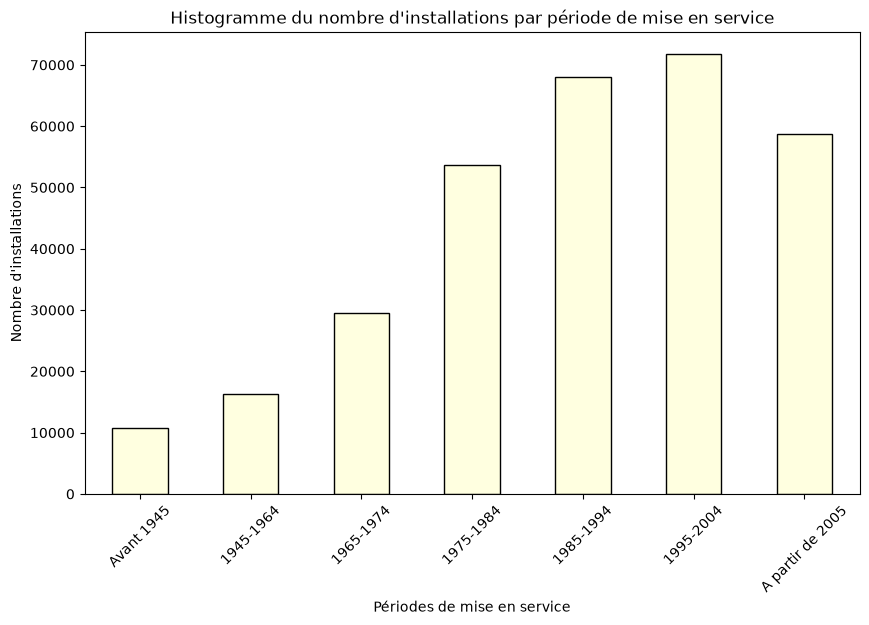

Part de données libellées : 93.0 %


In [11]:
# Compter les occurrences de chaque période de mise en service
period_counts = recensement['equip_service_periode'].value_counts()

# Ordre croissant
sorted_index = ['A partir de 2005'] + [p for p in period_counts.index if p != 'A partir de 2005']
period_counts = period_counts.reindex(sorted_index[::-1])

# Tracer l'histogramme
plt.figure(figsize=(10, 6))
period_counts.plot(kind='bar', color='#FFFFE0', edgecolor='black')
plt.title('Histogramme du nombre d\'installations par période de mise en service')
plt.xlabel('Périodes de mise en service')
plt.ylabel('Nombre d\'installations')
plt.xticks(rotation=45)
plt.show()

print('Part de données libellées :', round(period_counts.sum() / len(recensement), 2)*100, '%')

<div style="text-align: justify;">
<div style="text-align: justify; line-height: 1.8;">
Cet histogramme nous renseigne sur le nombre d'équipements mis en service selon la période. On remarque alors que la grande majorité des infrastructures a été mise en service à partir de 1975, et que le nombre d'équipements mis en service est croissant entre chaque période de 1945 à 2004 puis décroissant. Ainsi, nous pouvons noter que les équipements de la base sont globalement d'ancienneté hétérogène.

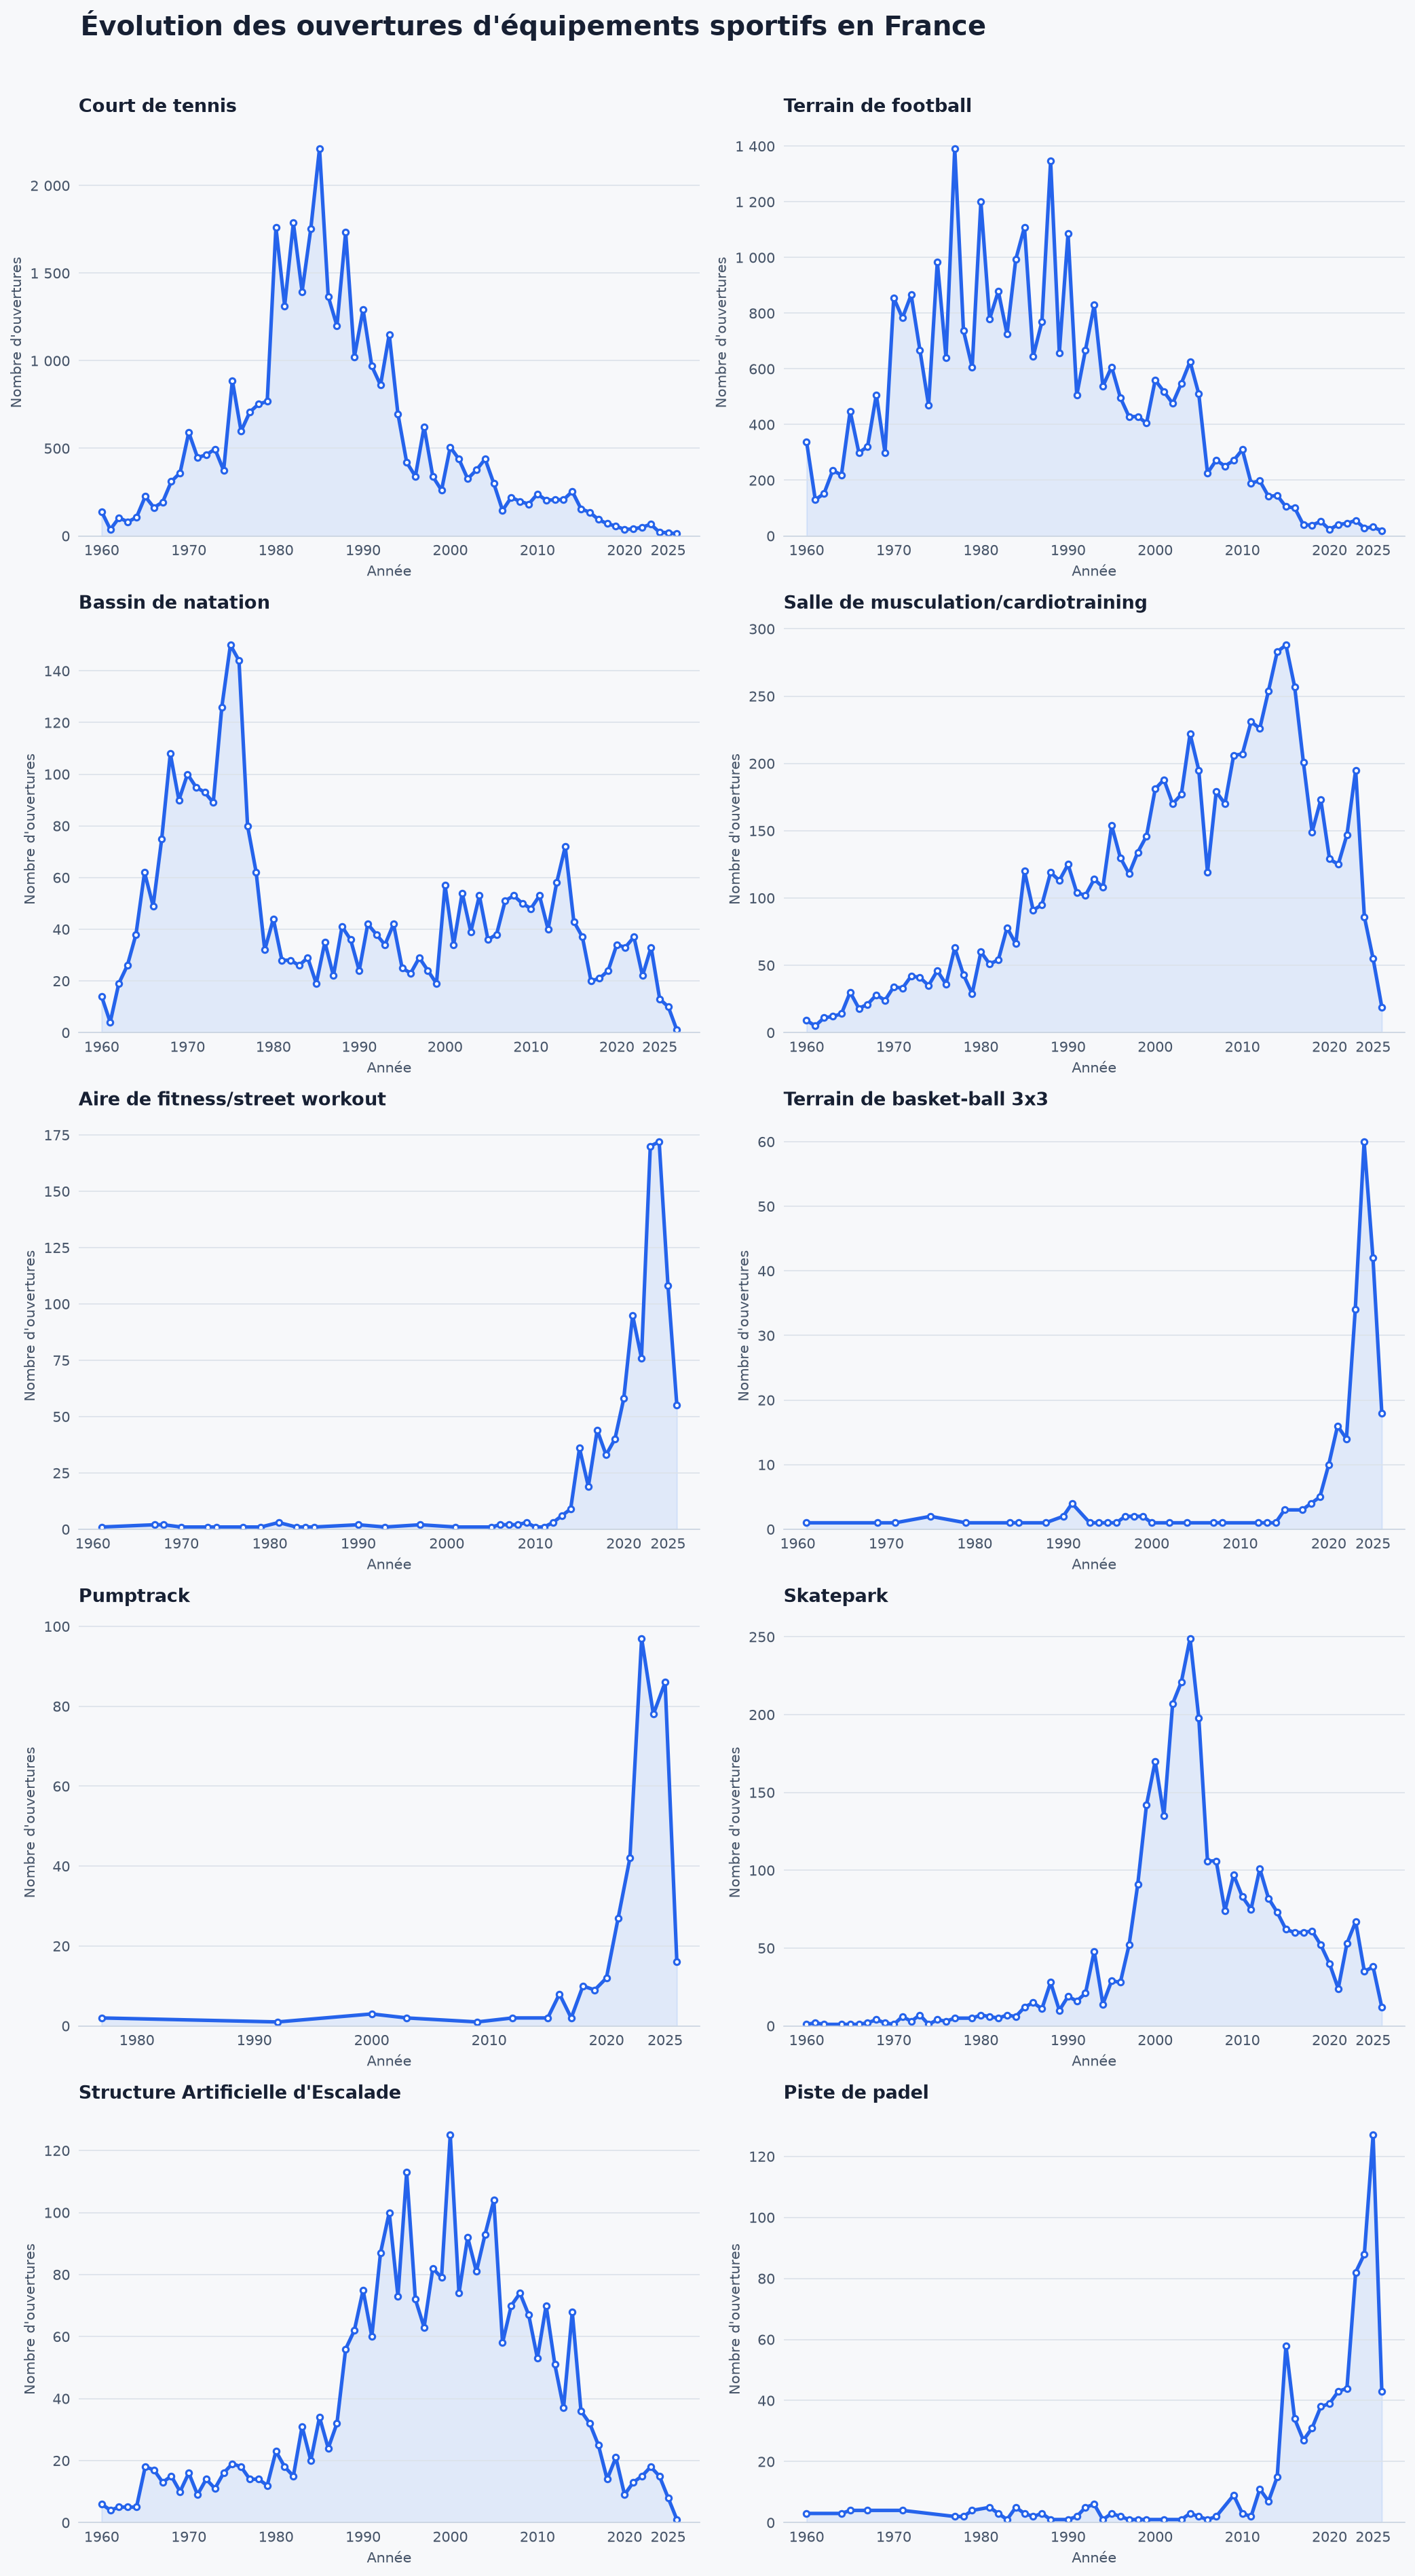

In [12]:
# 1. Choisir les équipements à afficher
groupes_equipements = {
    "Court de tennis": ["Court de tennis"],
    "Terrain de football": ["Terrain de football"],
    "Bassin de natation": [
        "Bassin mixte de natation",
        "Bassin sportif de natation"
    ],
    "Salle de musculation/cardiotraining": [
        "Salle de musculation/cardiotraining"
    ],
    "Aire de fitness/street workout": [
            "Aire de fitness/street workout"
    ],
    "Terrain de basket-ball 3x3": ["Terrain de basket-ball 3x3"],
    "Pumptrack": ["Pumptrack"],
    "Skatepark": ["Skatepark"],
    "Structure Artificielle d'Escalade": [
        "Structure Artificielle d'Escalade"
    ],
    "Piste de padel": ["Piste de padel"],
}

# 2. Préparer les données
df = recensement.copy()

df = df.dropna(subset=["equip_service_date", "equip_type_name"])

# Filtrer à partir de l'année 1960 pour avoir des échelles comparables
df = df[df["equip_service_date"] >= 1960]

# 3. Créer une grille de graphiques
ncols = 2
nrows = math.ceil(len(groupes_equipements) / ncols)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(14, 5 * nrows),
    dpi=150,
    squeeze=False
)

fig.patch.set_facecolor("#F7F8FA")

for i, (nom_groupe, liste_equipements) in enumerate(groupes_equipements.items()):
    ax = axes.flat[i]
    ax.set_facecolor("#F7F8FA")

    # Filtrer et compter les ouvertures par année
    data = df[df["equip_type_name"].isin(liste_equipements)]

    ouvertures = data.groupby("equip_service_date").size().reset_index(name="nombre_ouvertures")

    if ouvertures.empty:
        ax.set_title(f"{nom_groupe} — aucune donnée")
        ax.axis("off")
        continue

    x = ouvertures["equip_service_date"]
    y = ouvertures["nombre_ouvertures"]

    # Courbe et zone colorée
    ax.fill_between(x, y, color="#3B82F6", alpha=0.12)
    ax.plot(
        x, y,
        color="#2563EB",
        linewidth=2.5,
        marker="o",
        markersize=4,
        markerfacecolor="white",
        markeredgewidth=1.5,
        markeredgecolor="#2563EB"
    )

    # Titres et axes
    ax.set_title(
        nom_groupe,
        loc="left",
        fontsize=13,
        fontweight="bold",
        color="#172033",
        pad=12
    )
    ax.set_xlabel("Année", color="#475569")
    ax.set_xticks(sorted(set(ax.get_xticks()) | {2025}))
    ax.set_ylabel("Nombre d'ouvertures", color="#475569")
    ax.set_ylim(bottom=0)

    ax.yaxis.set_major_formatter(
        ticker.FuncFormatter(
            lambda val, pos: f"{val:,.0f}".replace(",", " ")
        )
    )

    ax.grid(axis="y", color="#DCE2EA", linewidth=0.8)
    ax.grid(axis="x", visible=False)
    ax.tick_params(axis="both", length=0, colors="#475569", pad=6)

    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)
    ax.spines["bottom"].set_color("#CBD5E1")

    ax.margins(x=0.04, y=0.15)

# Masquer les cases inutilisées si le nombre est impair
for j in range(len(groupes_equipements), nrows * ncols):
    axes.flat[j].set_visible(False)

fig.suptitle(
    "Évolution des ouvertures d'équipements sportifs en France",
    x=0.06, y=1.01,
    ha="left",
    fontsize=19,
    fontweight="bold",
    color="#172033"
)

plt.tight_layout()
plt.show()

<div style="text-align: justify;">
<div style="text-align: justify; line-height: 1.8;">

Les deux premiers graphiques représentent des équipements sportifs largement fournis en France, comme nous le verons sur les cartes suivantes, et qui ont des évolutions similaires. A partir des années 1960, un nombre important de terrains est construit, pour atteindre un pic dans les années 1980 puis de baisser continuellement jusqu'à aujourd'hui. A ce propos, on remarque que très peu de courts de tennis ou de terrains de football ont été construits dans les cinq dernières années, ce qui peut être le signe soit de la durabilité de ces équipements, soit d'une distribution satisfaisante sur le territoire, soit de la concentration des investissements vers d'autres équipements.


Le graphique sur les bassins de natation révèle beaucoup de choses, car on distingue nettement un pic au milieu des années 1970, qui correspond à l'opération **"1000 piscines"** réalisée par la secrétariat d'Etat à la Jeunesse et aux Sports lancé en 1969 afin d'apprendre à tous les enfants du pays à nager. Le podcast Une histoire particulière de Lou Quevauvillers (https://www.radiofrance.fr/franceculture/podcasts/serie-grand-plongeon-dans-la-piscine-tournesol) revient sur cette politique publique, qui a notamment conduit à la construction de 183 piscines Tournesol en France. Cependant, le parc de bassins de natation est vieillissant, comme on peut le voir par le plus faible nombre d'ouvertures depuis 1980.


Le graphique sur les salles de musculation est intéressant également car il témoigne bien de l'implantation de ce type d'équipements en France, avec des ouvertures progressives et un pic au milieu des années 2010, puis un essoufflement et très peu d'ouvertures depuis 2025.


Les trois graphiques suivants - aire de fitness, terrain de basket-ball 3x3, pumptrack - renseignement aussi sur une politique publique liée aux Jeux Olympiques de Paris 2024, qui est le **programme "5 000 équipements - Génération 2024"** lancé en 2023. Ce programme éponyme aide les collectivités territoriales et les fédérations pour un montant maximum de 500 000 euros, ce qui limite la capacité d'investissement. C'est pourquoi a essaimé sur le territoire des petits équipements sportifs, au sens beaucoup moins grand qu'un terrain de foot par exemple, librement accessibles, et cela d'autant plus que le basket-ball 3x3 était présent au JO. Cela rappelle fortement la période d'aménagement des skateparks dans les années 1990, qui ont été, en réalité, inadaptés aux pratiques réels et aujourd'hui delaissé, comme le soulignent Benjamin Pélican et Romain Lepillé (https://hal.science/hal-05592295).


Enfin, deux graphiques concernent des sports dits "à la mode" - l'escalade et le padel. Pour l'escalade, quand on regarde le graphique on ne voit pas spécialement d'effet de mode, mais quand on ne regarde que les établissements privés commerciaux, on ne distingue pas de pic clair. Alors que pour le padel, on voit bien le pic très récent pour l'installation de pistes de padel alors même qu'il n'y en avait quasiment pas en France jusqu'en 2010.

## C. **Les équipements sportifs sont-ils en accès libre ?**

In [13]:
counts_inst = (
    recensement.groupby("dep_nom")["inst_numero"]
    .nunique()
    .reset_index(name="count_inst")
)

counts_equip = (
    recensement.groupby("dep_nom")["equip_numero"]
    .nunique()
    .reset_index(name="count_equip")
)

counts_acc_libre = (
    recensement.groupby("dep_nom")["equip_acc_libre"]
    .sum()
    .reset_index(name="count_acc_libre")
)

counts = (
    counts_inst
    .merge(counts_equip, on="dep_nom")
    .merge(counts_acc_libre, on="dep_nom")
)

# Calcul des ratios
counts["ratio_equip_inst"] = (
    counts["count_equip"] / counts["count_inst"]
)

counts["ratio_acc_libre"] = (
    counts["count_acc_libre"] / counts["count_equip"]
).round(2)

In [14]:
top_inst = (
    recensement.groupby(["inst_numero", "inst_nom", "dep_nom"])["equip_numero"]
    .nunique()
    .reset_index(name="nb_equipements")
    .sort_values("nb_equipements", ascending=False)
)

print(top_inst.head(10))

       inst_numero                                           inst_nom  \
135450  I851910073                         COMPLEXE DES TERRES NOIRES   
120125  I751160055                             LAGARDERE PARIS RACING   
125532  I785020004                                      LES PYRAMIDES   
3683    I030230014                    Centre Omnisports Pierre Coulon   
144718  I940170001  PARC INTERDEPARTEMENTAL DES SPORTS ET DE LOISI...   
144915  I940280070  PARC INTERDEPARTEMENTAL DES SPORTS DE CHOISY L...   
50163   I340030035                     Centre International de Tennis   
48041   I330630034                   PLAINE DES SPORTS COLETTE BESSON   
48174   I330750007                   COMPLEXE SPORTIF ALBERT GALINIER   
35872   I270380002                                       Center Parcs   

             dep_nom  nb_equipements  
135450        Vendée              59  
120125         Paris              59  
125532      Yvelines              54  
3683          Allier              50  
1

<div style="text-align: justify;">
<div style="text-align: justify; line-height: 1.8;">

Ici, on a la liste des 10 installations de France qui comptent le plus grand nombre d'équipements. Il s'agit notamment de **grands espaces** qui comportent plusieurs équipes de type "Divers équipements Sports de nature" ou alors des grands **complexes sportifs** regroupant plusieurs salles. Cela nous donne une première idée de la philosophie générale de cette base, qui consiste à allier un niveau de détail très important concernant l'équipement en question et une vue d'ensemble générale sur les installations et la mise en relation des équipements entre eux. Nous essaierons dans la suite de ce travail d'explorer parfois les installations, et parfois les équipements.

Dans la cellule de code suivante, on charge le fonds de carte avec les limites départementales, et on réalise quelques opérations pour obtenir un résultat exploitable pour la suite.

In [15]:
# URL de la ressource (fichier GeoJSON)
url2 = "https://www.data.gouv.fr/fr/datasets/r/eb36371a-761d-44a8-93ec-3d728bec17ce"

# Télécharger le fichier GeoJSON
response = requests.get(url2)

# Charger le fichier dans un GeoDataFrame
gdf = gpd.read_file(BytesIO(response.content))

# Création d'un nouvel objet sans les départements d'outre-mer
gdf_metropole = gdf[~gdf['code_insee'].str.startswith('97')]  # Exclure les départements d'outre-mer

# Renommer le département
gdf_metropole["nom"] = gdf_metropole["nom"].replace(
    "Territoire-de-Belfort",
    "Territoire de Belfort"
)

# Fusion de la Métropole de Lyon avec le département du Rhône
masque = gdf_metropole["nom"].isin([
    "Rhône",
    "Métropole de Lyon"
])

# Donner aux deux entités le même nom
gdf_metropole.loc[masque, "nom"] = "Rhône"

# Fusionner leurs géométries
gdf_metropole = gdf_metropole.dissolve(by="nom", as_index=False)

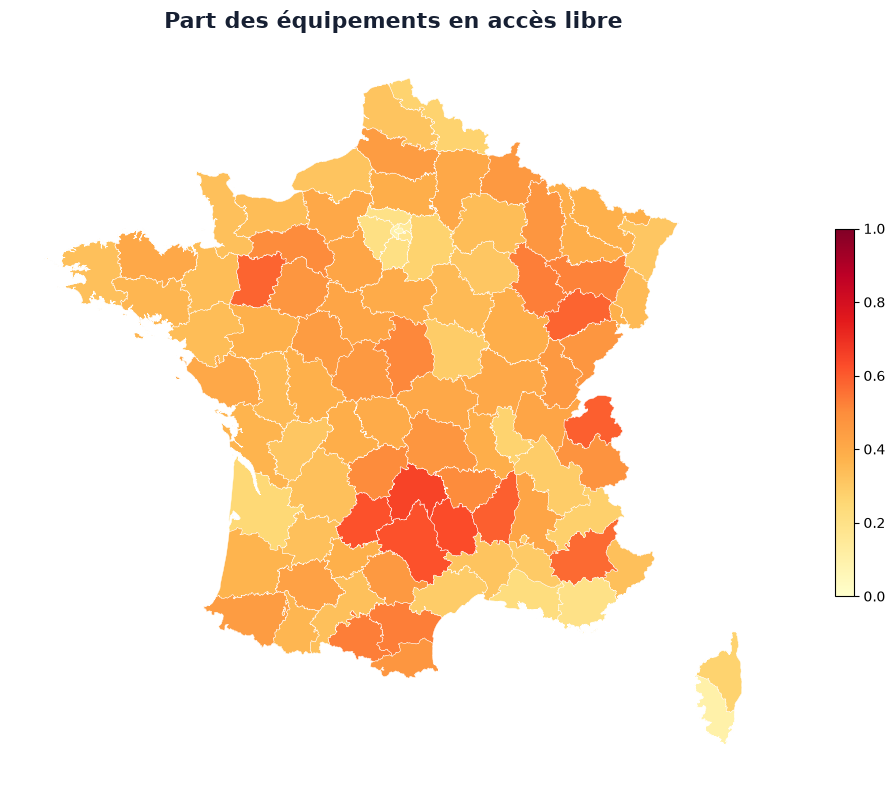

In [16]:
# Cartes choroplèthes des ratios par département
# Utiliser gdf comme fond de carte et lui rattacher les ratios de counts
cartes = gdf_metropole.merge(
    counts,
    left_on="nom",
    right_on="dep_nom",
    how="left",
)

fig, ax = plt.subplots(figsize=(12, 8))

cartes.plot(
    ax=ax,
    column="ratio_acc_libre",
    cmap="YlOrRd",
    vmin=0,
    vmax=1,
    legend=True,
    edgecolor="white",
    linewidth=0.3,
    legend_kwds={
        "label": None,
        "orientation": "vertical",
        "shrink": 0.5,
    }
)

ax.set_title("Part des équipements en accès libre", fontsize=16, fontweight="bold", color="#172033", pad=12)
ax.set_axis_off()

plt.tight_layout()
plt.show()

<div style="text-align: justify;">
<div style="text-align: justify; line-height: 1.8;">

Cette carte montre la proportion par département des équipements en accès libre, c'est-à-dire accessible 24h/24h sans restriction. Un point saillant de cette carte porte sur l'Île-de-France avec une proportion plus faible que sur le reste du territoire d'équipements en accès libre. Le reste du territoire le orange domine, ce qui signifie qu'environ la moitié des équipements sportifs est en accès libre. 

## D. **Quels sont les types d'équipements sportifs en France ?**

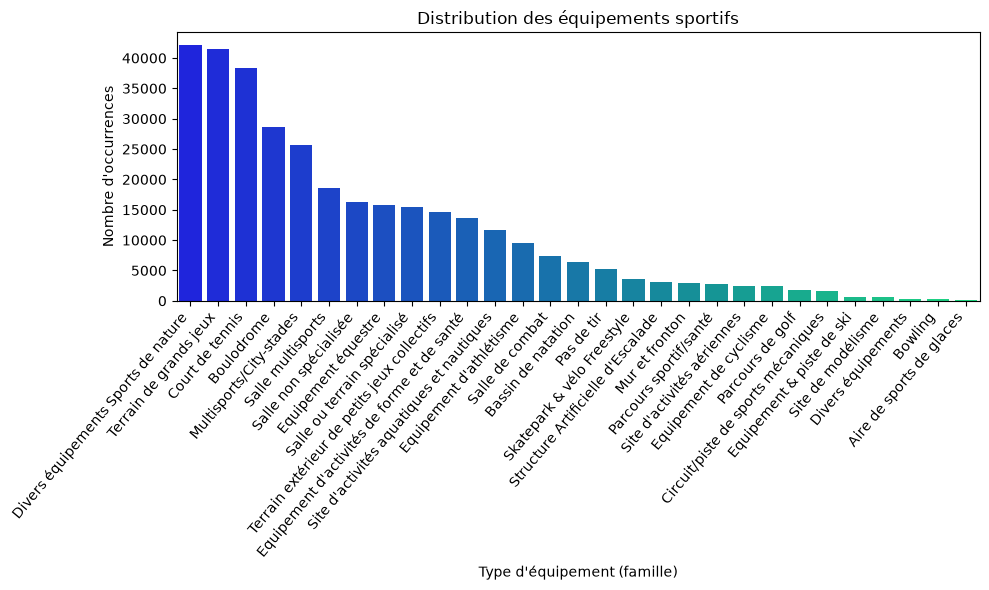

In [17]:
# Créer une table de fréquences
freq_table = pd.DataFrame(recensement['equip_type_famille'].value_counts()).reset_index()
freq_table.columns = ['Var1', 'Freq']

# Visualiser avec un barplot
plt.figure(figsize=(10, 6))
sns.barplot(x='Var1', y='Freq', hue='Var1', data=freq_table.sort_values('Freq', ascending=False), palette='winter')
plt.title("Distribution des équipements sportifs")
plt.xlabel("Type d'équipement (famille)")
plt.ylabel("Nombre d'occurrences")
plt.xticks(rotation=50, ha='right')
plt.tight_layout()
plt.show()

<div style="text-align: justify;">
<div style="text-align: justify; line-height: 1.8;">

Cet histogramme représente la distribution des familles d'équipements sportifs. A l'intérieur de ces 29 familles, il existe 183 noms d'équipements sportifs. Certaines familles contiennent plusieurs noms d'équipements sportifs comme les terrains de grands jeux, qui font références à 8 équipements sportifs différents bien que les terrains de football dominent largement cette famille. La famille Divers équipements Sport de nature rassemble, quant à elle, des équipements très différents les uns des autres comme des boucles de randonnée et des pistes de char à voile. A l'inverse, la famille bowling ne contient que les bowlings.

Un point peut paraître suprenant, en France, on dénombre autant de bassins de natation que de pas de tir quasiment. Aussi, un équipement sur trois en France est soit issu des Sports de nature, des grands jeux ou du tennis

In [18]:
equipement = ['Terrain de grands jeux', 'Divers équipements Sports de nature', 'Bowling']

for i in equipement:
    recensement_equipement = recensement[recensement['equip_type_famille'] == i].copy()
    tableau_comptage = recensement_equipement['equip_type_name'].value_counts().reset_index()
    print(f"\n{i} :")
    print(f"\n{tableau_comptage}")


Terrain de grands jeux :

                 equip_type_name  count
0            Terrain de football  36350
1               Terrain de rugby   2580
2                  Terrain mixte   2234
3  Terrain de baseball /softball    140
4    Terrain de hockey sur gazon     53
5        Terrain de rugby à XIII     35
6  Terrain de football américain     22
7             Terrain de cricket     20

Divers équipements Sports de nature :

                                      equip_type_name  count
0                                 Boucle de randonnée  29456
1                    Espace de pratique spéléologique   3098
2                          Site d'escalade en falaise   3015
3        Site de spéléologie sportive et/ou éducative   1937
4                                              Canyon   1298
5   Parcours Acrobatique en Hauteur/Site d'accrobr...    756
6               Parcours fixe de course d’orientation    739
7                                  Refuge de montagne    585
8                       

# III. Cartes

## A. **Grandes tendances**

On se restreint aux équipements sportifs en France métropolitaine

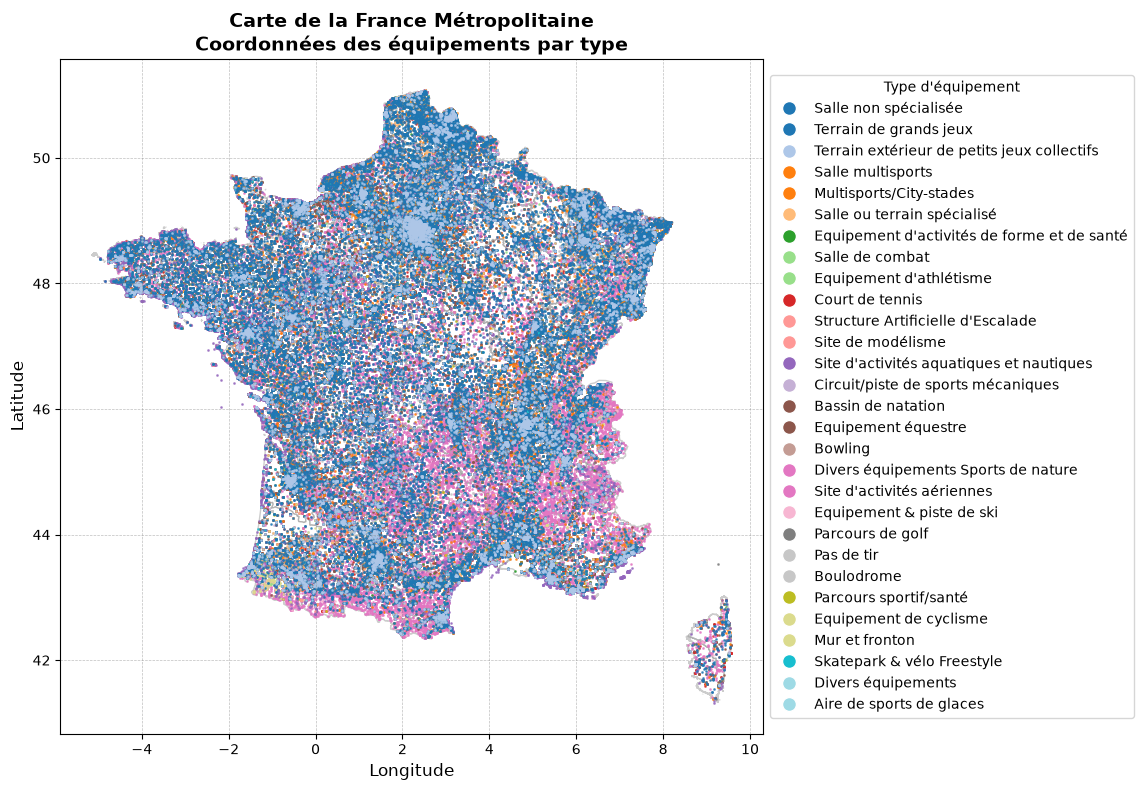

In [19]:
# Filtrer les points qui ne sont pas en métropole
recensement_metropole = recensement[
    (recensement['equip_x'] >= -5) & 
    (recensement['equip_x'] <= 10) & 
    (recensement['equip_y'] >= 41) & 
    (recensement['equip_y'] <= 52)
].copy()

# Générer une table de couleurs pour les familles d'équipements
equip_types = recensement_metropole['equip_type_famille'].unique()
cmap = plt.get_cmap("tab20", len(equip_types))  # Table de couleurs qualitative
color_dict = {etype: cmap(i) for i, etype in enumerate(equip_types)}

# Attribuer des couleurs à chaque type d'équipement
recensement_metropole['color'] = recensement_metropole['equip_type_famille'].map(color_dict)

# Tracer la carte
fig, ax = plt.subplots(figsize=(12, 8))

# Fond de carte de la France métropolitaine
gdf_metropole.plot(ax=ax, color='white', edgecolor='gray', alpha=0.4)

# Tracer les points pour chaque équipement
for equip_type, group in recensement_metropole.groupby('equip_type_famille'):
    ax.scatter(
        group['equip_x'],
        group['equip_y'],
        color=color_dict[equip_type],
        s=1,  # Taille
        alpha=0.7,
        label=equip_type
    )

# Légende sur mesure avec taille des points plus grosse
legend_handles = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor=color_dict[equip_type],
           markersize=10, label=equip_type)  # Taille plus grosse
    for equip_type in recensement_metropole['equip_type_famille'].unique()
]

# Ajouter la légende sur mesure
ax.legend(
    handles=legend_handles,
    title="Type d'équipement",
    loc='center left',
    bbox_to_anchor=(1, 0.5),
    frameon=True
)

plt.title('Carte de la France Métropolitaine\nCoordonnées des équipements par type', fontsize=14, weight='bold')
plt.xlabel('Longitude', fontsize=12)
plt.ylabel('Latitude', fontsize=12)
plt.grid(color='gray', linestyle='--', linewidth=0.5, alpha=0.5)
plt.tight_layout()
plt.show()

<div style="text-align: justify;">
<div style="text-align: justify; line-height: 1.8;">

Nous avons tracé une carte qui affiche tous les points sur le territoire français. Ces points correspondent aux équipements recensés, et les couleurs correspondent aux différentes familles d'équipement. A partir de cette carte on peut déjà inférer quelques tendances : 

- le rouge est largement prédominant ce qui signifie qu'une grande majorité de d'infrastructures rentrent dans la catégorie "Terrains de grands jeux". De plus, notons que le rouge est plutôt homogène sur le territoire bien qu'il soit moins présent sur la partie Sud de celui-ci.
- le bleu foncé est également une couleur qui domine sur cette carte. Cela permet de visualiser la quantité importante d'équipements de type "Multisports / City-stades" et "divers équipements sport et nature" présentes sur le territoire notamment sur la partie Sud. 
- nous remarquons également que certaines parties du territoires sont moins dotées en infrastructures (Corse, Landes, Manche, Camargue, diagonale du vide...)


<div style="text-align: justify;">
<div style="text-align: justify; line-height: 1.8;">
Quand on ne trace que les points associés à la famille d'équipements "Mur et fronton", la carte confirme notre intuition, que les murs et frontons sont concentrés dans le sud-est, là où la pelote basque y est très développée. De même, il y en a beaucoup à Paris, ce qui n'est pas étonnant car il y a aussi des murs simples de tennis dans cette modalité et ce type d'installation est courant en Ile de France. 

Un autre exemple est celui des terrains de quilles, qui sont localisés aux endroits où les jeux de quilles sont partie intégrant de la culture locale comme dans le département de l'Aveyron, avec les quilles de 8, ou dans le nord-est.

<div style="text-align: justify;">
<div style="text-align: justify; line-height: 1.8;">
Pour les terrains de grands jeux, qui regroupent en particulier les terrains de football, on voit des concentrations au niveau des grandes villes françaises, ainsi que dans le Nord et l'Est.

<div style="text-align: justify;">
<div style="text-align: justify; line-height: 1.8;">
En ce qui concerne les boulodromes, on voit aussi des disparités régionales, qui correspondent aux différents jeux de boule. Dans le Sud-Est et dans le Nord, on joue à la pétanque, mais des jeux tels que la boule lyonnaise sont pratiqués dans le Dauphiné ou la boule nantaise dans la région du Val-de-Loire. La faible quantité de boulodromes dans le Sud-Est peut-être due à la non comptabilisation des terrains de pétanque privés.

<div style="text-align: justify;">
<div style="text-align: justify; line-height: 1.8;">
Comme attendu, nous remarquons que les équipements de ski sont concentrées dans les régions montagneuses : Jura, Alpes, Pyrénées, Vosges et Massif-Central. --> Je voudrais insister dans cette partie qu'il y a des infrastructures qui sont liés à des traditions régionales (pelote basque), mais aussi à des spécificités territoriales (ski), d'où un contrôle qu'il faut faire dans les régressions, et que c'est pas aussi facile que ça de traiter le problème.

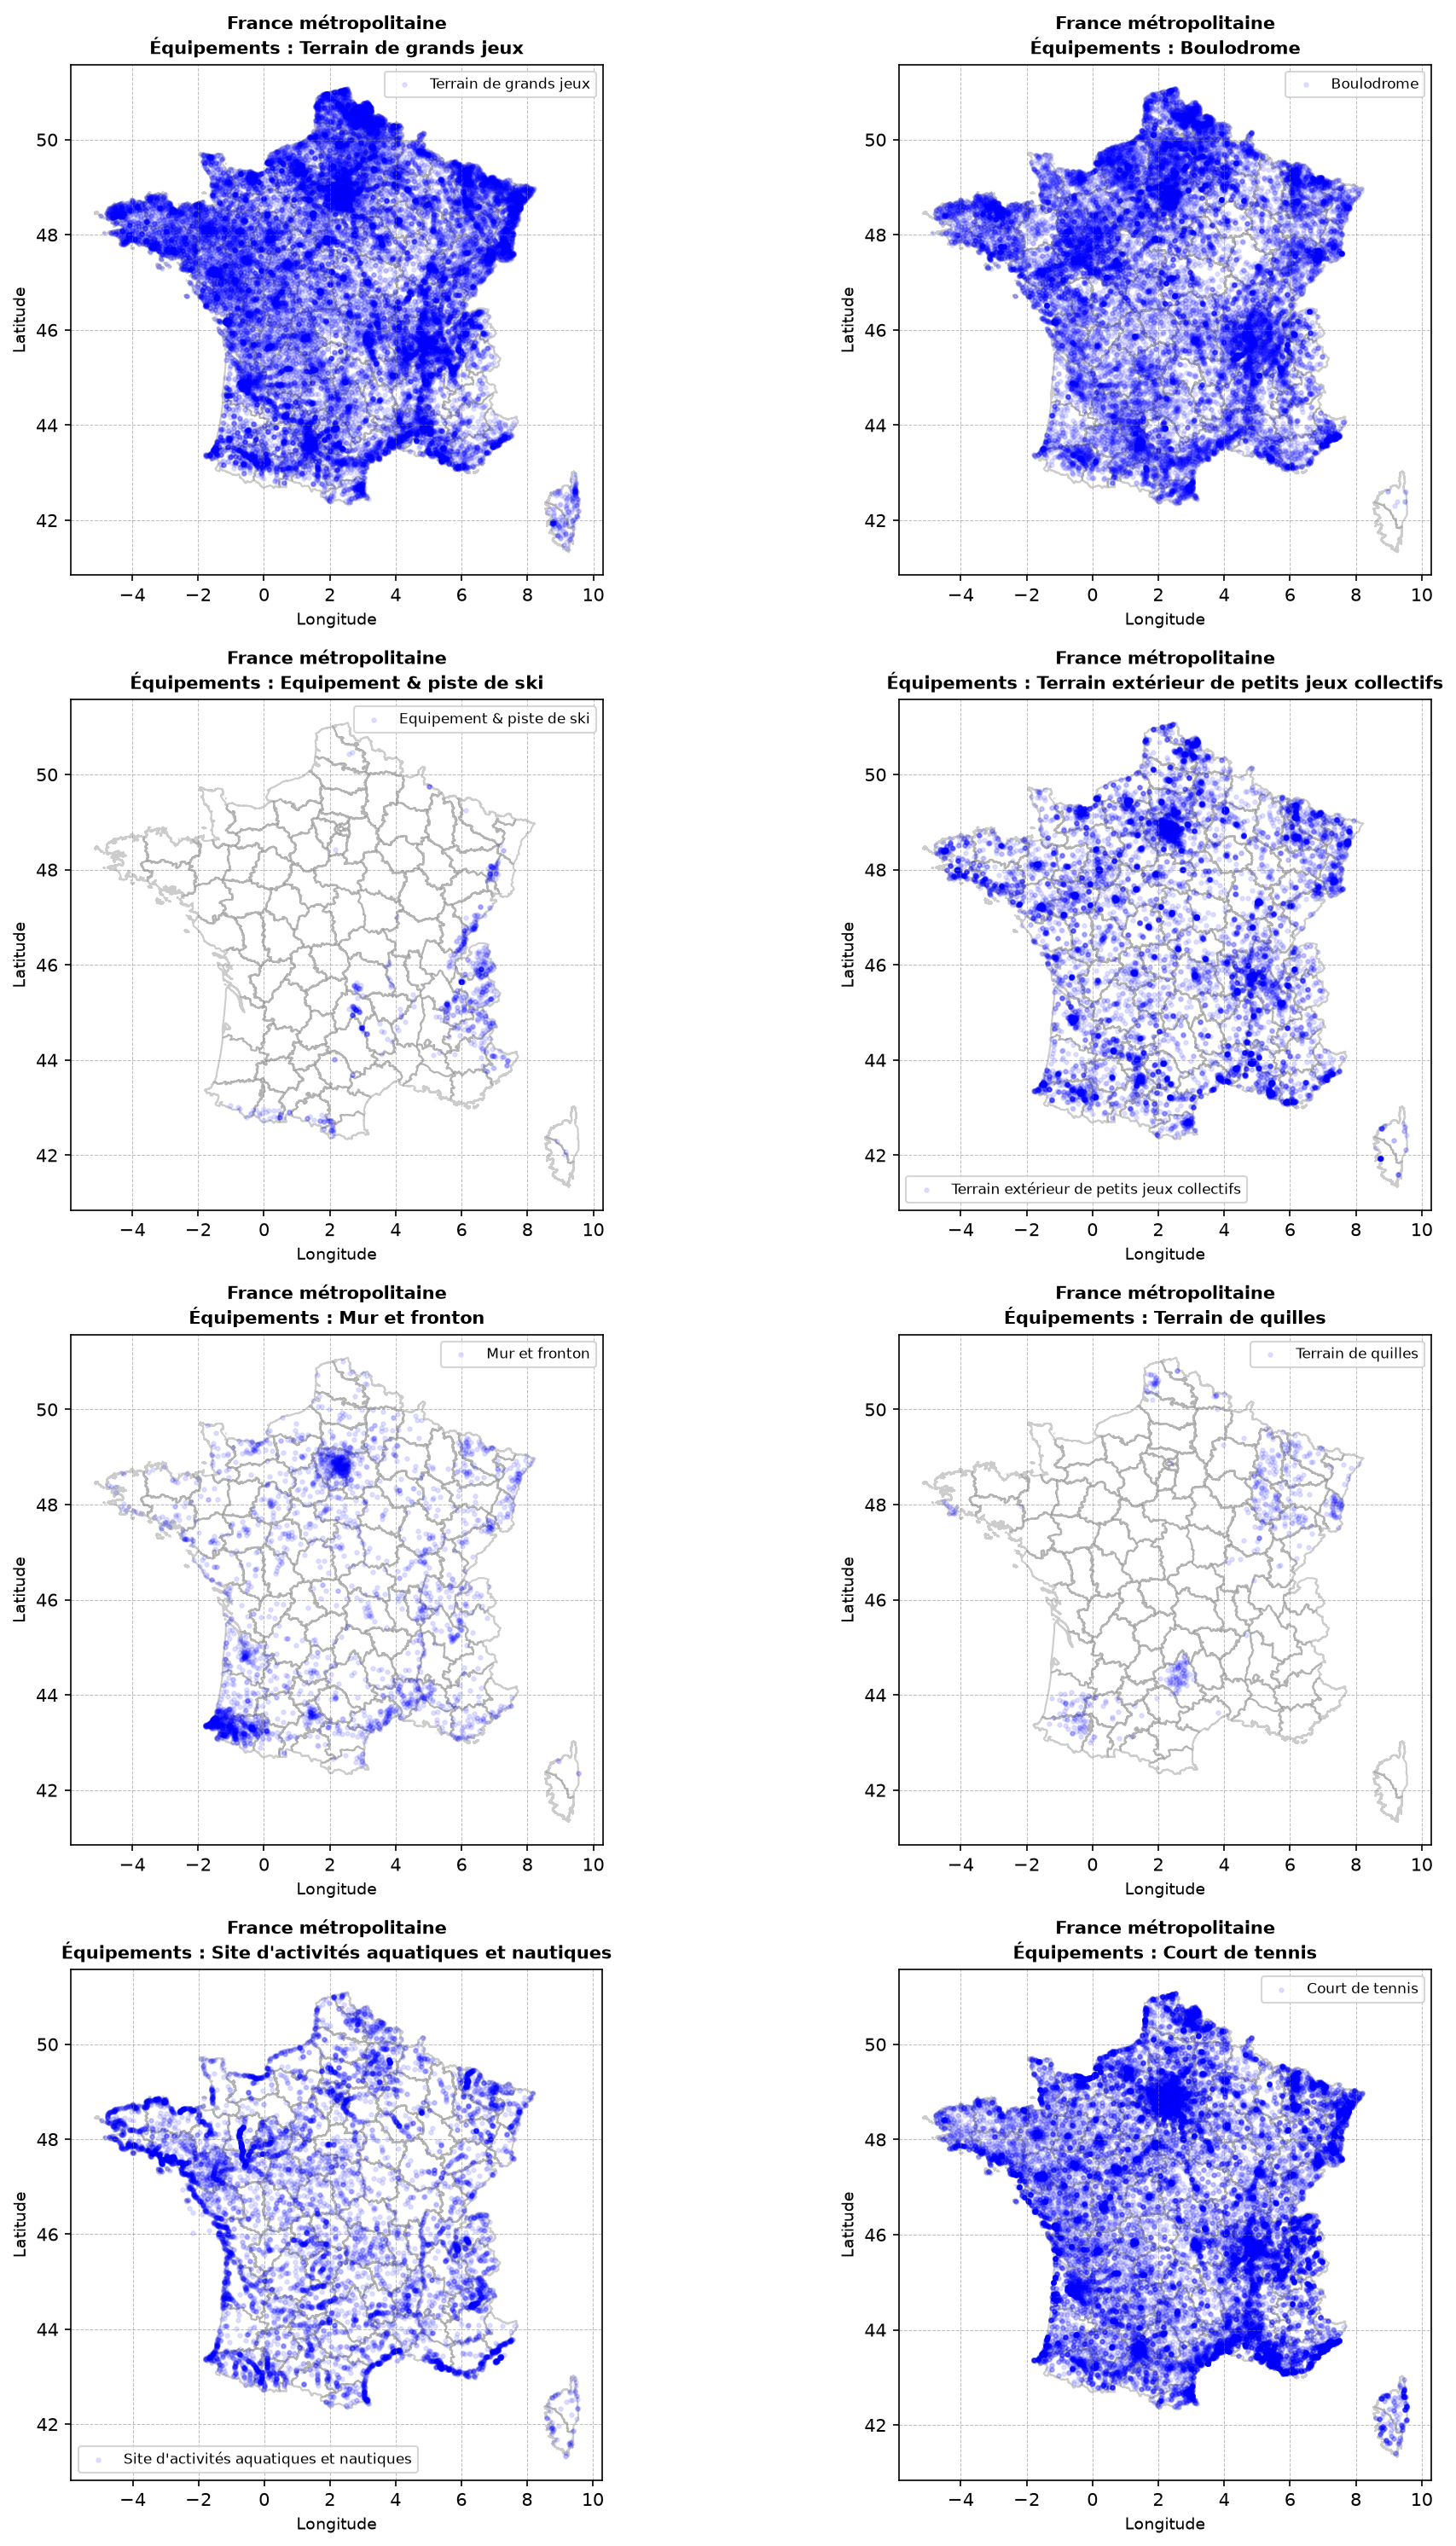

In [ ]:
familles = [
    "Terrain de grands jeux",
    "Boulodrome",
    "Equipement & piste de ski",
    "Court de tennis",
    "Mur et fronton",
    "Terrain de quilles",
    "Site d'activités aquatiques et nautiques",
    "Terrain extérieur de petits jeux collectifs"
]

# 1. Créer une grille de graphiques sur 2 colonnes
ncols = 2
nrows = math.ceil(len(familles) / ncols)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(14, 5 * nrows),
    dpi=150,
    squeeze=False
)

# 2. Parcourir les familles et créer les cartes
for i, famille in enumerate(familles):

    ax = axes[i // ncols, i % ncols]

    # Filtrer les équipements
    donnees = recensement_metropole[
        recensement_metropole["equip_type_famille"] == famille
    ]

    # Cas particulier : Terrain de quilles
    if famille == "Terrain de quilles":
        donnees = recensement_metropole[
            recensement_metropole["equip_type_name"] == famille
        ]

    # Afficher le fond de carte
    gdf_metropole.plot(
        ax=ax,
        color="white",
        edgecolor="gray",
        alpha=0.4
    )

    # Afficher les équipements
    ax.scatter(
        donnees["equip_x"],
        donnees["equip_y"],
        color="blue",
        s=5,
        alpha=0.1,
        label=famille
    )

    # Personnaliser la carte
    ax.set_title(
        f"France métropolitaine\nÉquipements : {famille}",
        fontsize=10,
        weight="bold"
    )

    ax.set_xlabel("Longitude", fontsize=9)
    ax.set_ylabel("Latitude", fontsize=9)

    ax.grid(
        color="gray",
        linestyle="--",
        linewidth=0.5,
        alpha=0.5
    )

    ax.legend(fontsize=8)

# 3. Supprimer les axes inutilisés s'il y en a
for j in range(len(familles), nrows * ncols):
    fig.delaxes(axes[j // ncols, j % ncols])

# 4. Ajuster la disposition et afficher
plt.tight_layout()
plt.show()

<div style="text-align: justify;">
<div style="text-align: justify; line-height: 1.8;">
Nous pouvons remarquer que les "Terrains extérieurs de petits jeux collectifs" sont principalement présents dans les grandes métropoles et notamment en Ile de France. Cela peut s'expliquer par le fait que la modalité "Terrains extérieurs de petits jeux collectifs" concentre principalement des terrains de baskets et d'autres petites infrastructures idéales pour les zones urbaines dans lesquelles il y a peu de place. 

<div style="text-align: justify;">
<div style="text-align: justify; line-height: 1.8;">
Cette étude de carte, selon différentes modalités nous permet d'établir différents critères déterminants du type d'infrastructures présentes au sein d'une zone géographique : 

- **Spécificités naturelles de la zone** : en effet, les éléments naturels spécifiques à une zone géographique peuvent permettre ou non certaines pratiques sportives. Par exemple, nous avons observer que les pistes de ski sont présentes en grande majorité dans les zones montagneuses. 
- **Spécificités géographique de la zone** : en effet, dans les zones très urbaines, où se trouve une forte densité de population et de construction, il n'est pas possible de construire de grandes infrastructures. Par exemple, en ville on trouve beaucoup de "terrains extérieurs de petits jeux collectifs".
- **Pratiques régionales de la zone** : en effet, les pratiques sportives spécifiques à certaines zones induisent un plus grand nombre d'infrastructure d'un certain type. Par exemple, la boule lyonnaise, la pétanque etc. 

## B. **Quel est le lien entre nombre de licenciés et nombre d'équipements sportifs ?**

Les nombres de licenciés par fédération sportive sont disponibles publiquement à l'échelle du département, et nous faisons l'hypothèse qu'il existe une relation linéaire entre la quantité d'infrastructures disponibles pour réaliser tel sport et le nombre de licenciés de la discipline associée. On fait ce travail pour 6 fédérations différentes : **Football, Tennis, Natation, Escalade, Bowling et Jeux de Quilles, Escalade, Tir et Equitation**

In [24]:
# Nom du DataFrame final : nom de la fédération
federations = {
    "df_licences_football": "111",
    "df_licences_tennis": "123",
    "df_licences_natation": "119",
    "df_licences_bowling": "213",
    "df_licences_escalade": "135",
    "df_licences_tir": "125",
    "df_licences_equitation": "109",
}

# Récupération des données dans une boucle
dfs_licences = {}

for nom_df, federation in federations.items():
    dfs_licences[nom_df] = recuperer_licences(federation)

    print(
        f"{nom_df} : "
        f"{len(dfs_licences[nom_df])} résultats récupérés"
    )

df_licences_football = dfs_licences["df_licences_football"]
df_licences_tennis = dfs_licences["df_licences_tennis"]
df_licences_natation = dfs_licences["df_licences_natation"]
df_licences_bowling = dfs_licences["df_licences_bowling"]
df_licences_escalade = dfs_licences["df_licences_escalade"]
df_licences_tir = dfs_licences["df_licences_tir"]
df_licences_equitation = dfs_licences["df_licences_equitation"]

df_licences_football : 110 résultats récupérés
df_licences_tennis : 110 résultats récupérés
df_licences_natation : 110 résultats récupérés
df_licences_bowling : 110 résultats récupérés
df_licences_escalade : 110 résultats récupérés
df_licences_tir : 110 résultats récupérés
df_licences_equitation : 110 résultats récupérés


Football : 36313 équipements


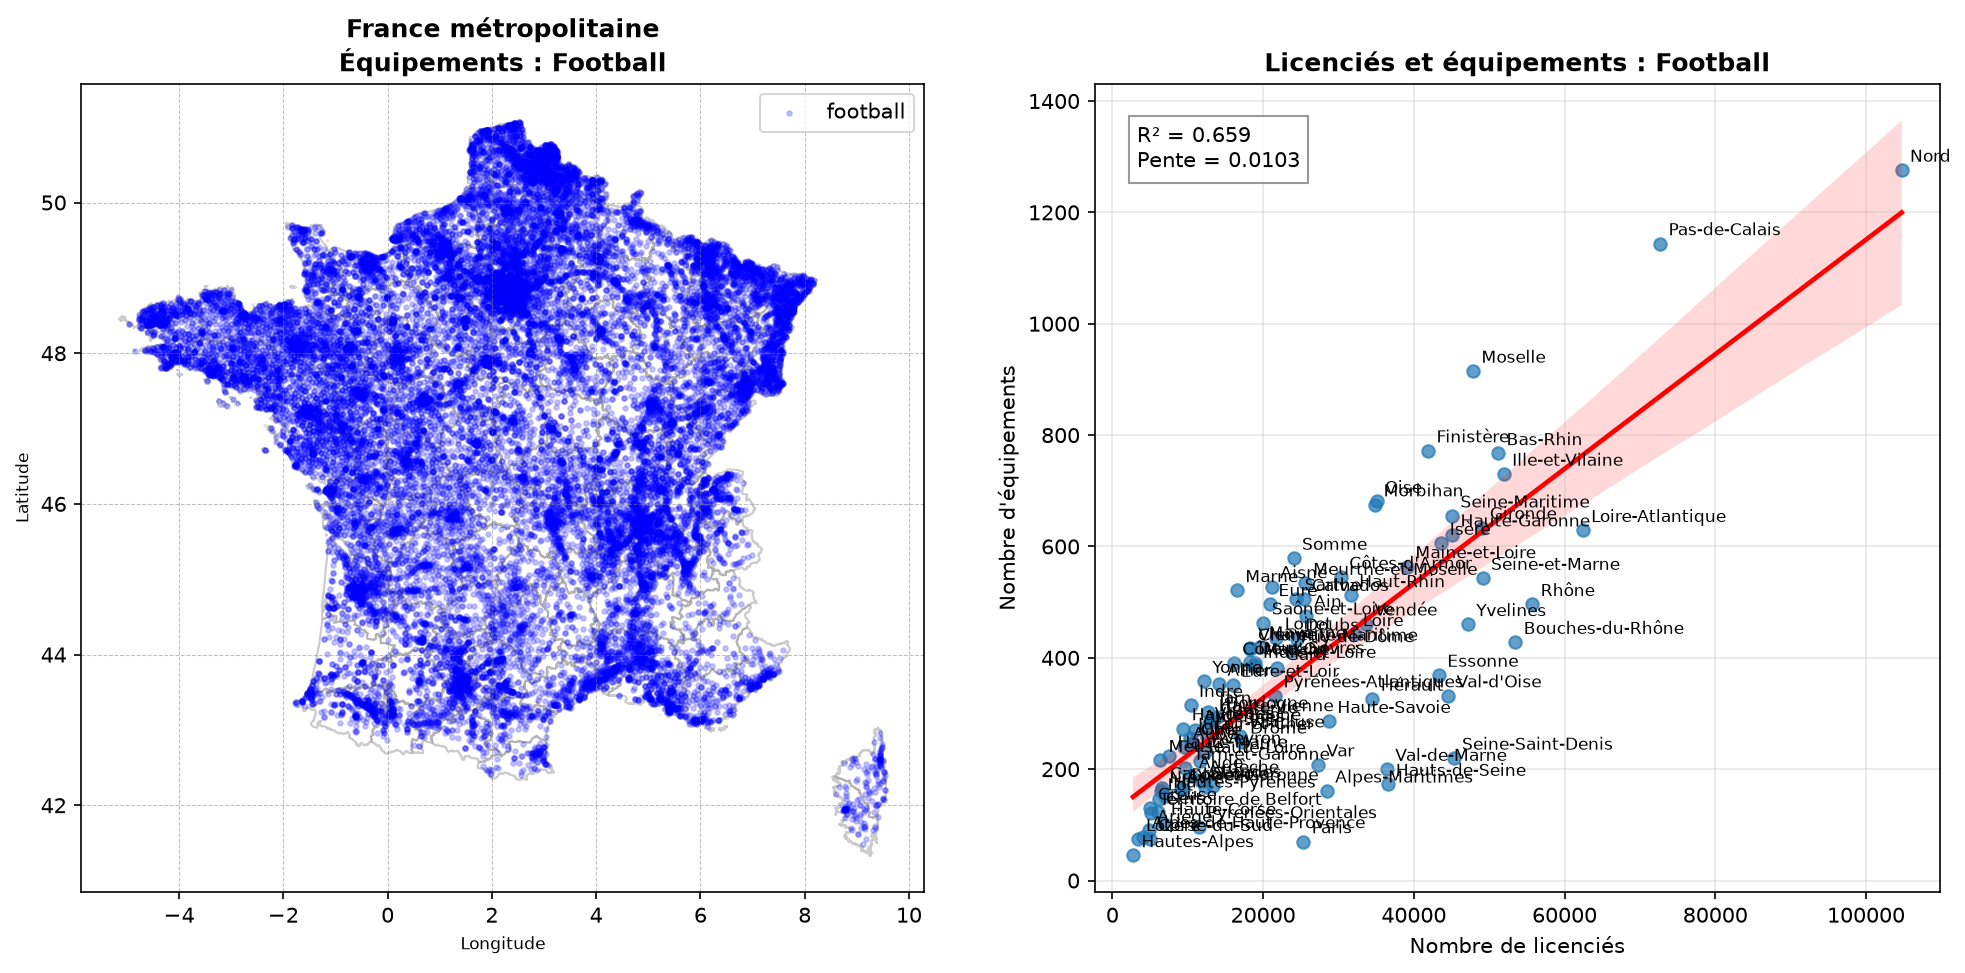

<Figure size 1000x600 with 0 Axes>

                            OLS Regression Results                            
Dep. Variable:     nombre_equipements   R-squared:                       0.821
Model:                            OLS   Adj. R-squared:                  0.817
Method:                 Least Squares   F-statistic:                     170.5
Date:                Sun, 18 Oct 2026   Prob (F-statistic):           7.74e-32
Time:                        03:09:30   Log-Likelihood:                -572.91
No. Observations:                  96   AIC:                             1152.
Df Residuals:                      93   BIC:                             1160.
Df Model:                           2                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        141.0034     13.366     10.550      0.0

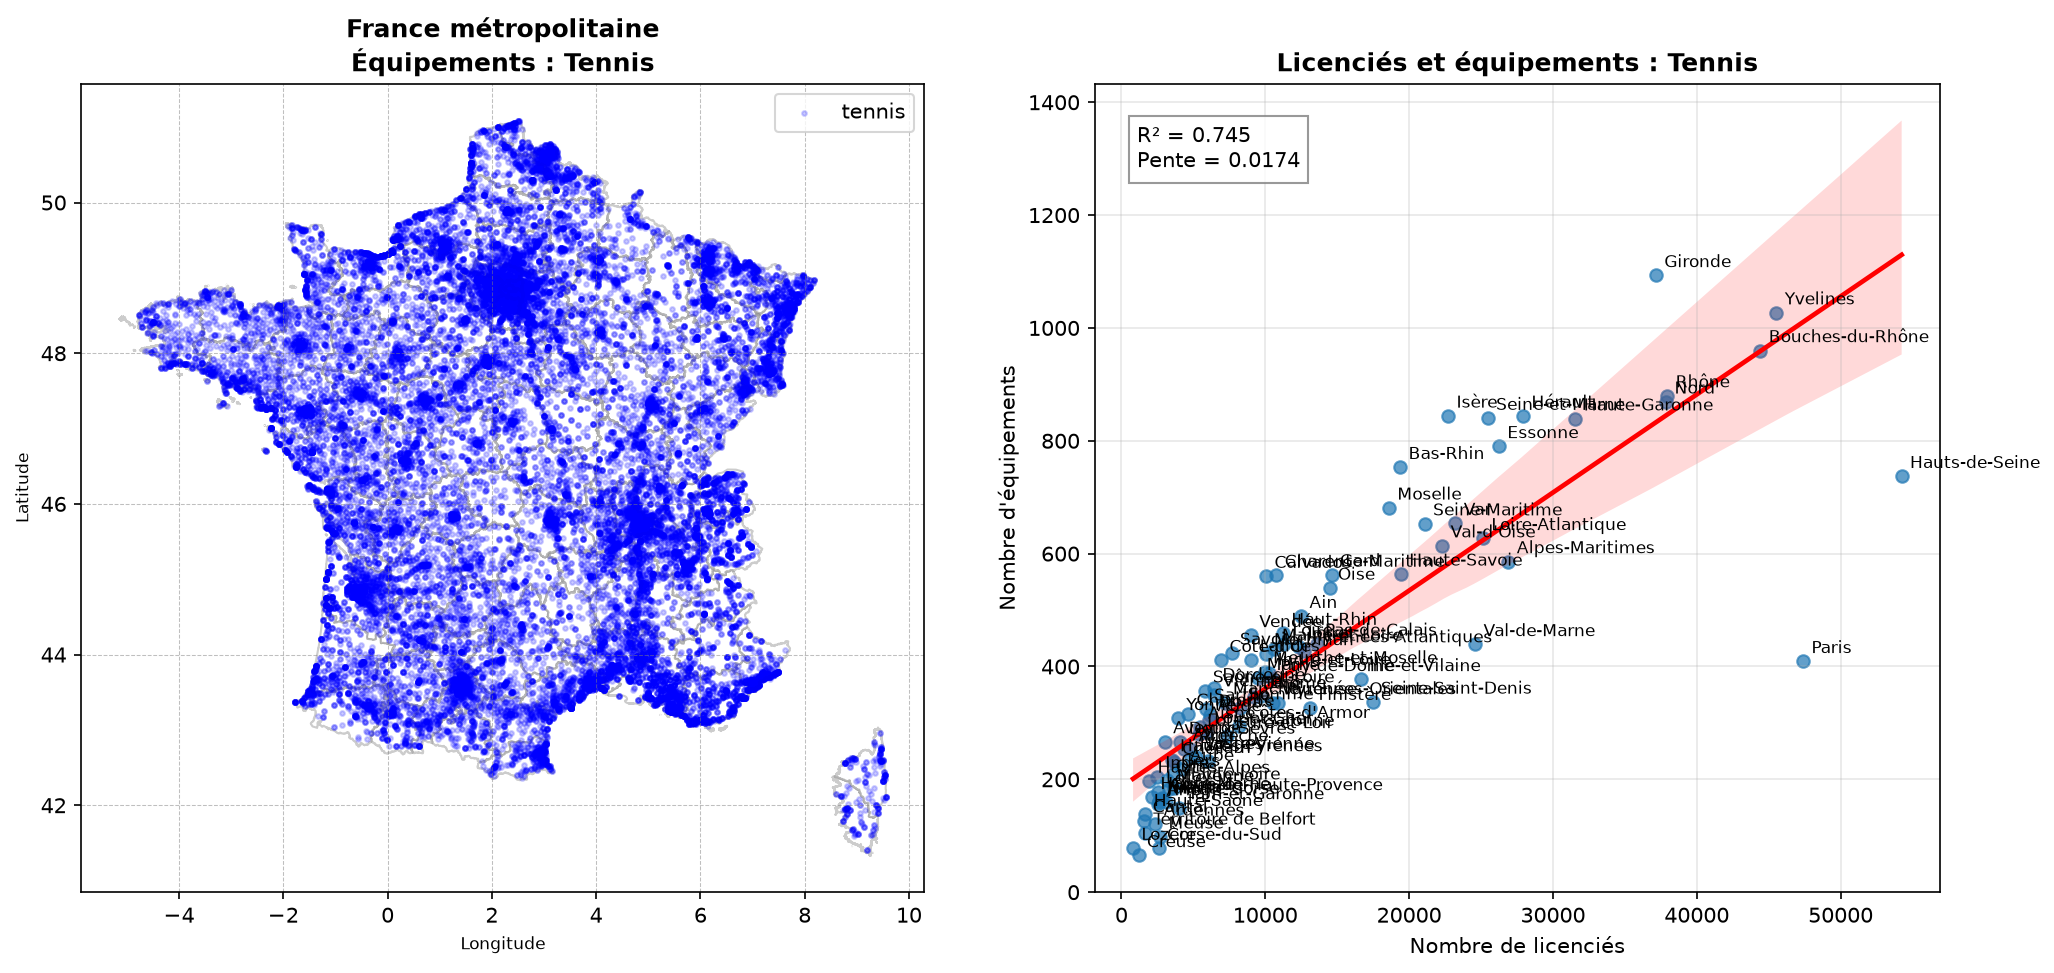

<Figure size 1000x600 with 0 Axes>

                            OLS Regression Results                            
Dep. Variable:     nombre_equipements   R-squared:                       0.764
Model:                            OLS   Adj. R-squared:                  0.759
Method:                 Least Squares   F-statistic:                     37.91
Date:                Sun, 18 Oct 2026   Prob (F-statistic):           9.12e-13
Time:                        03:09:31   Log-Likelihood:                -589.67
No. Observations:                  96   AIC:                             1185.
Df Residuals:                      93   BIC:                             1193.
Df Model:                           2                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        157.2343     21.059      7.466      0.0

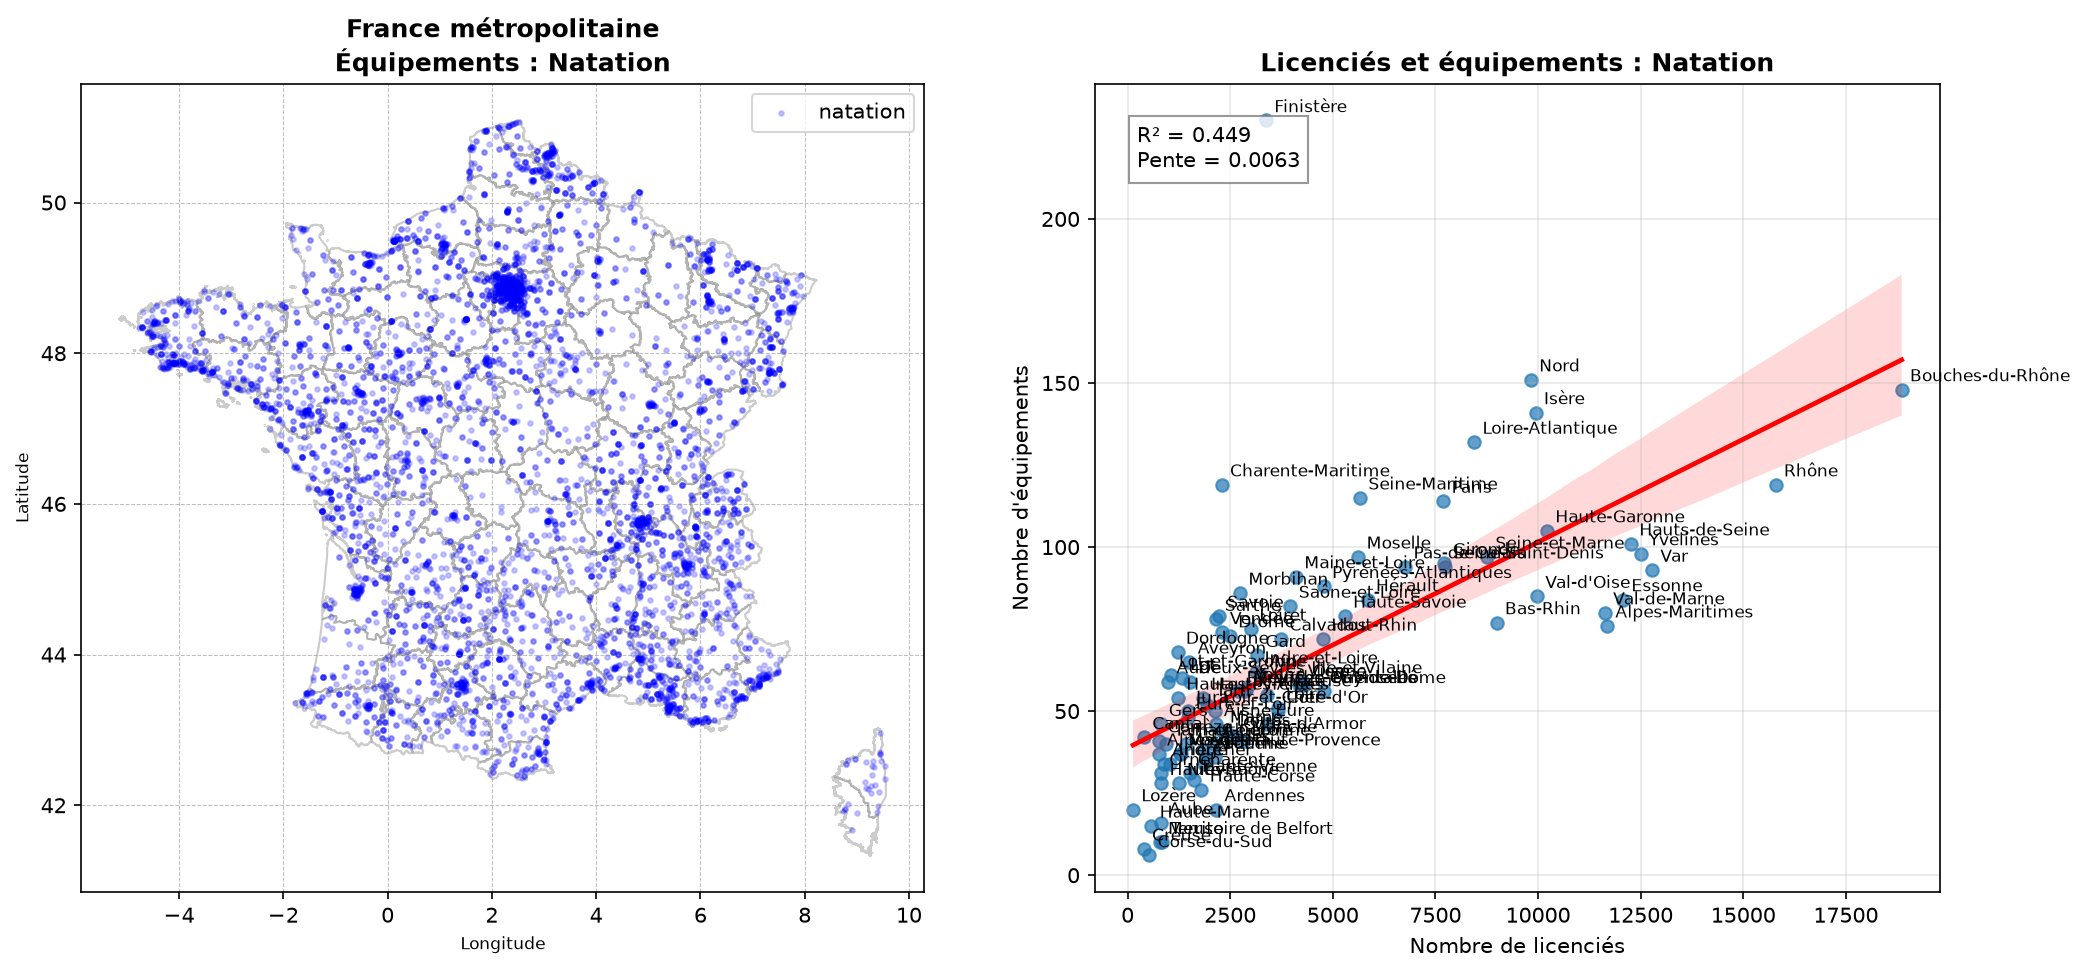

<Figure size 1000x600 with 0 Axes>

                            OLS Regression Results                            
Dep. Variable:     nombre_equipements   R-squared:                       0.595
Model:                            OLS   Adj. R-squared:                  0.586
Method:                 Least Squares   F-statistic:                     103.6
Date:                Sun, 18 Oct 2026   Prob (F-statistic):           2.19e-24
Time:                        03:09:32   Log-Likelihood:                -435.84
No. Observations:                  96   AIC:                             877.7
Df Residuals:                      93   BIC:                             885.4
Df Model:                           2                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         27.7224      2.931      9.457      0.0

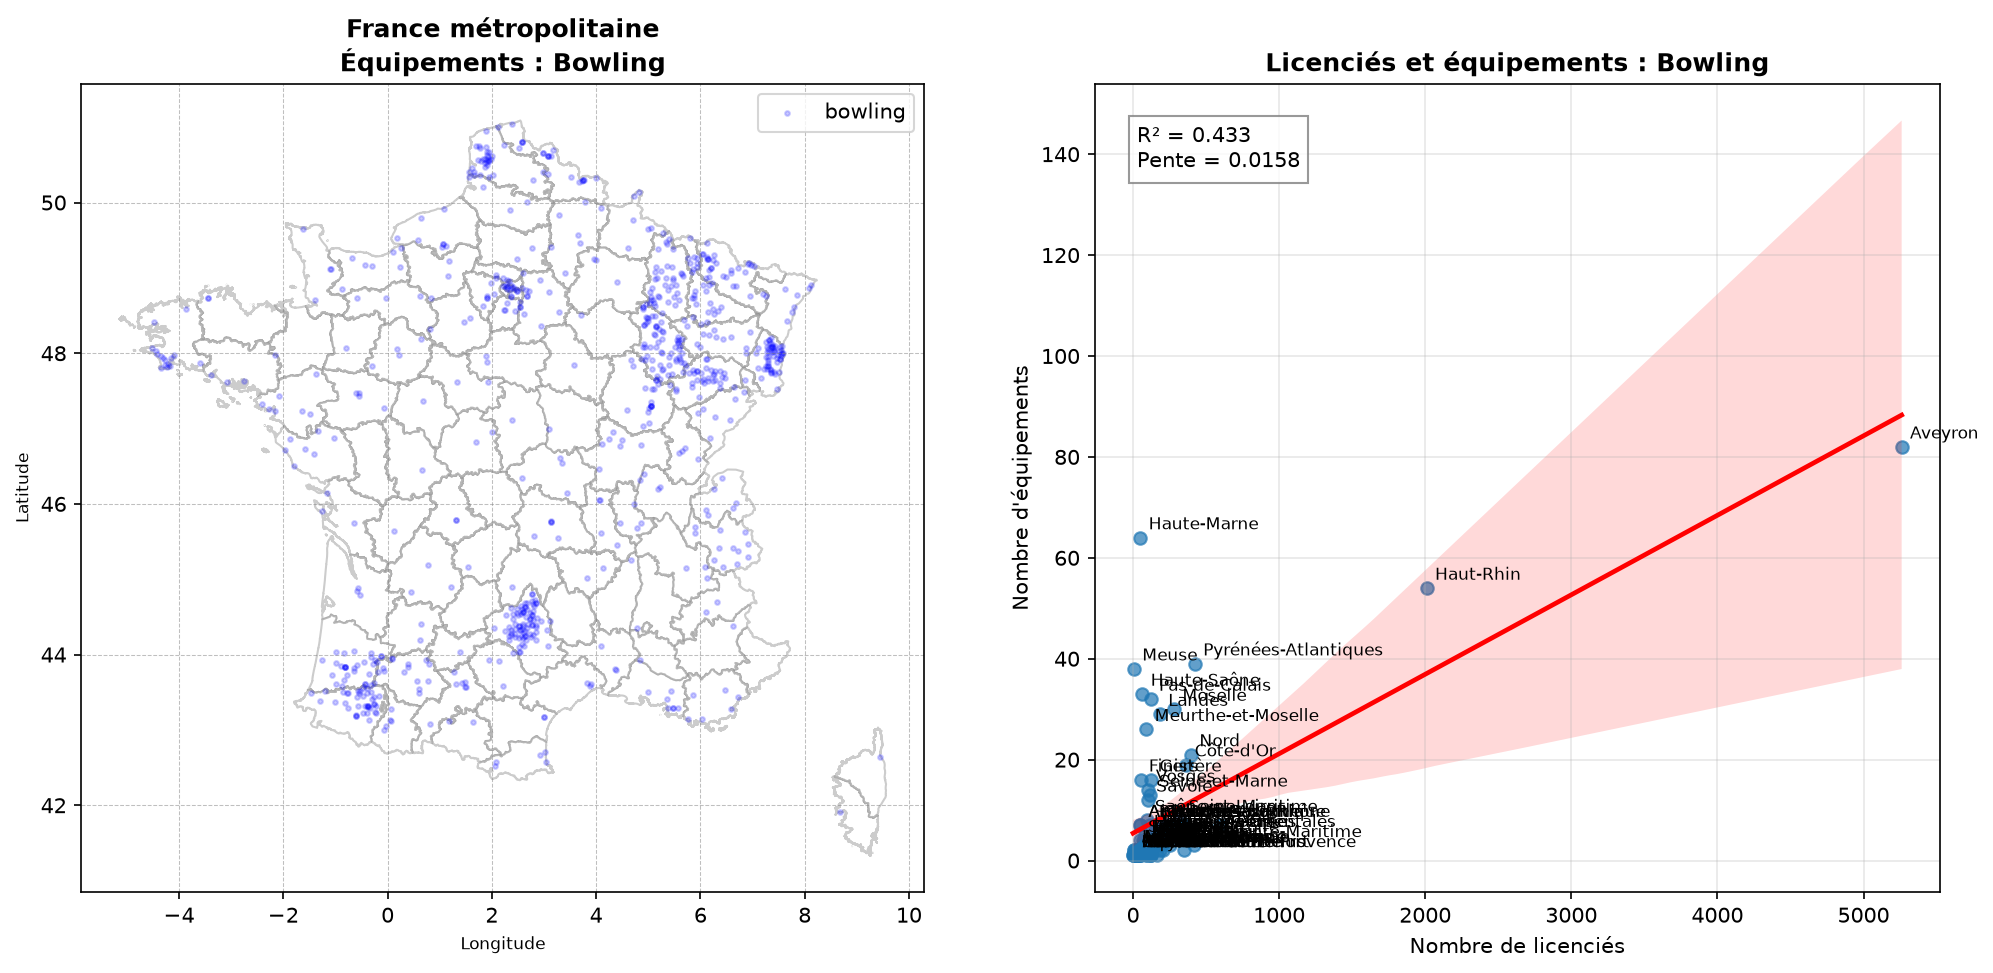

<Figure size 1000x600 with 0 Axes>

                            OLS Regression Results                            
Dep. Variable:     nombre_equipements   R-squared:                       0.434
Model:                            OLS   Adj. R-squared:                  0.421
Method:                 Least Squares   F-statistic:                     2.232
Date:                Sun, 18 Oct 2026   Prob (F-statistic):              0.113
Time:                        03:09:33   Log-Likelihood:                -338.95
No. Observations:                  90   AIC:                             683.9
Df Residuals:                      87   BIC:                             691.4
Df Model:                           2                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          5.6137      2.285      2.456      0.0

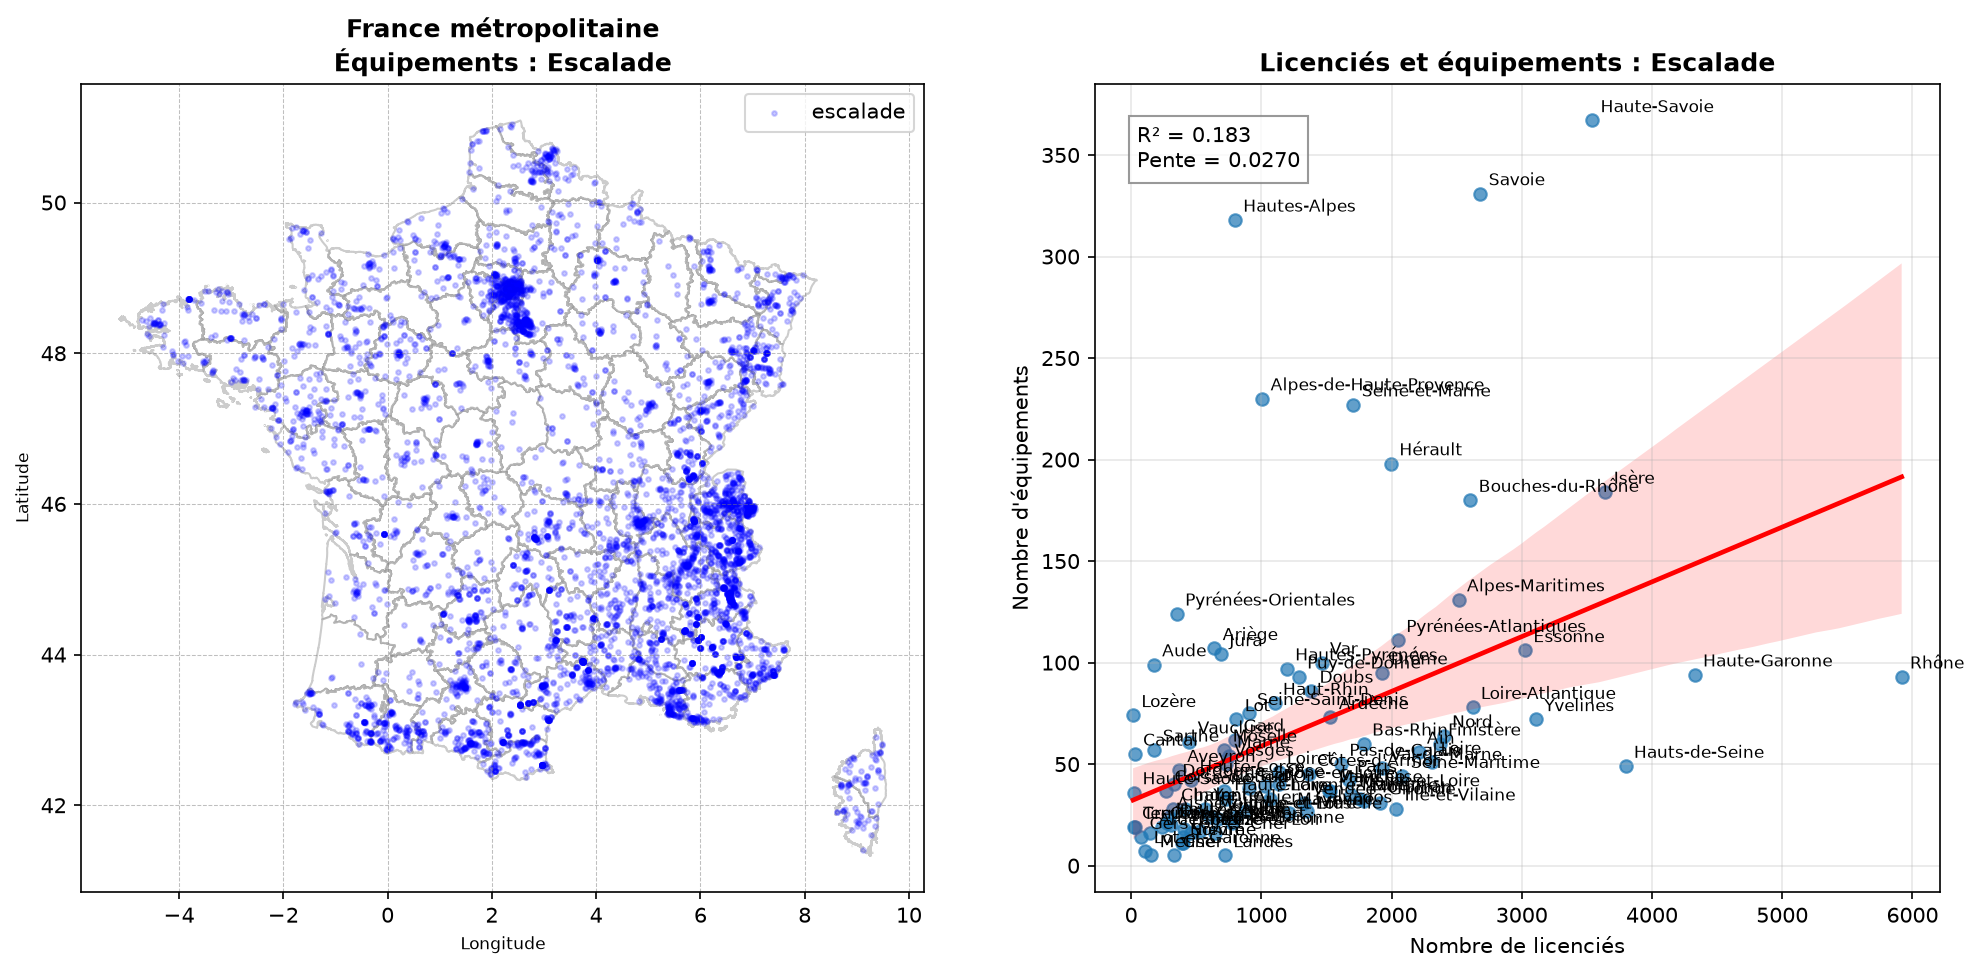

<Figure size 1000x600 with 0 Axes>

                            OLS Regression Results                            
Dep. Variable:     nombre_equipements   R-squared:                       0.210
Model:                            OLS   Adj. R-squared:                  0.193
Method:                 Least Squares   F-statistic:                     3.832
Date:                Sun, 18 Oct 2026   Prob (F-statistic):             0.0252
Time:                        03:09:35   Log-Likelihood:                -528.63
No. Observations:                  96   AIC:                             1063.
Df Residuals:                      93   BIC:                             1071.
Df Model:                           2                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         39.4216     10.594      3.721      0.0

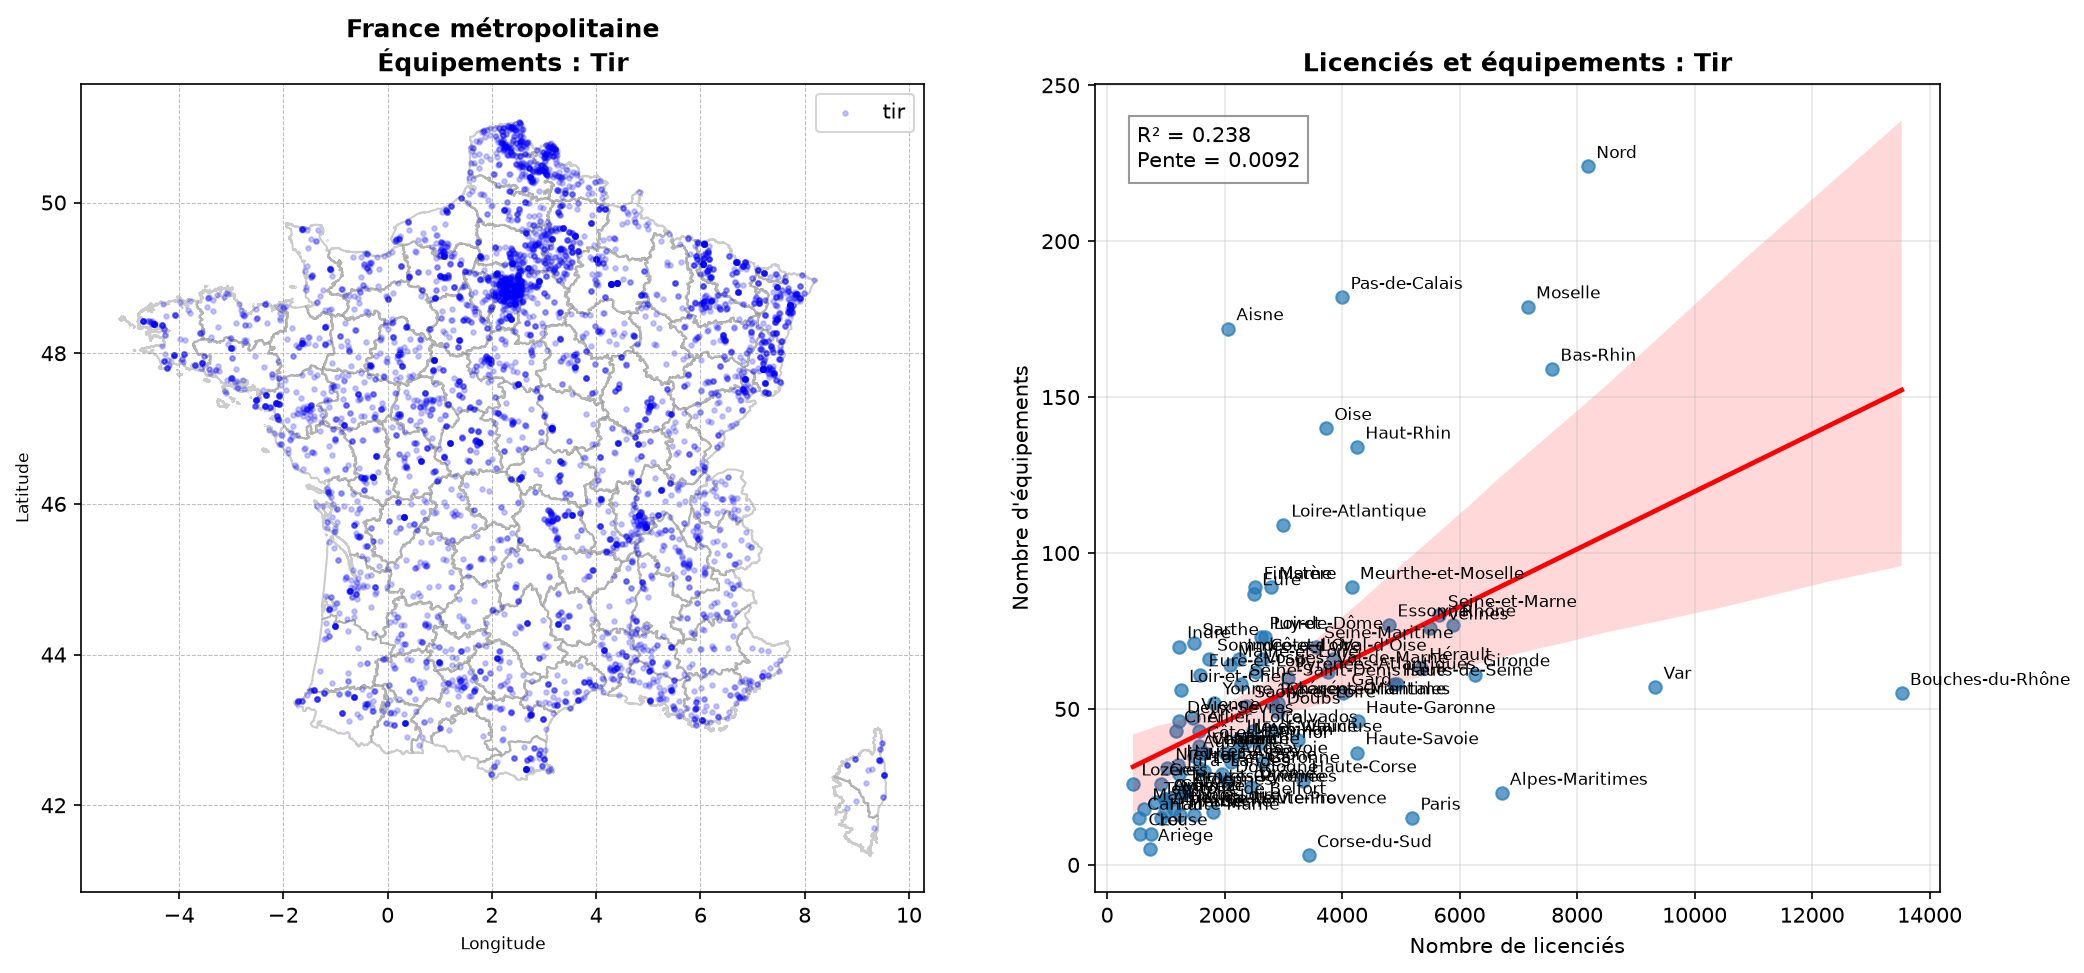

<Figure size 1000x600 with 0 Axes>

                            OLS Regression Results                            
Dep. Variable:     nombre_equipements   R-squared:                       0.300
Model:                            OLS   Adj. R-squared:                  0.285
Method:                 Least Squares   F-statistic:                     5.540
Date:                Sun, 18 Oct 2026   Prob (F-statistic):            0.00533
Time:                        03:09:36   Log-Likelihood:                -473.32
No. Observations:                  96   AIC:                             952.6
Df Residuals:                      93   BIC:                             960.3
Df Model:                           2                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         23.2907      8.105      2.874      0.0

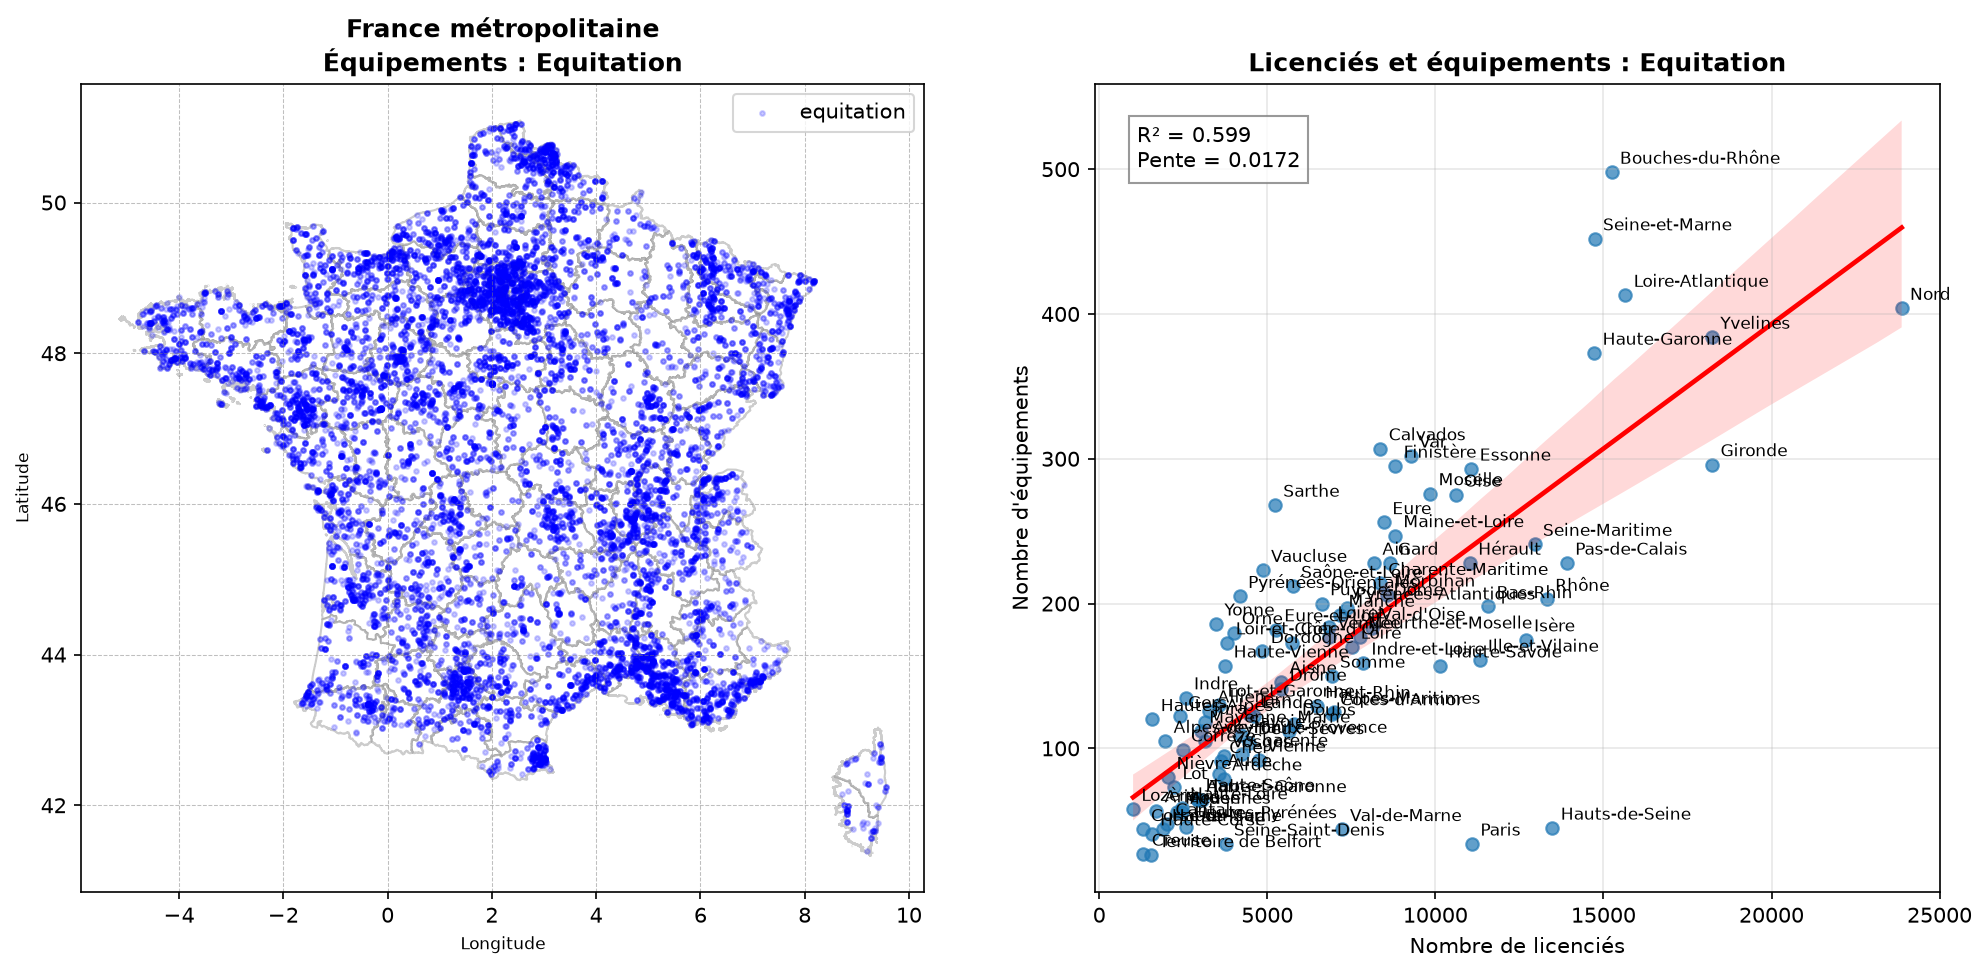

<Figure size 1000x600 with 0 Axes>

                            OLS Regression Results                            
Dep. Variable:     nombre_equipements   R-squared:                       0.642
Model:                            OLS   Adj. R-squared:                  0.635
Method:                 Least Squares   F-statistic:                     56.71
Date:                Sun, 18 Oct 2026   Prob (F-statistic):           7.92e-17
Time:                        03:09:37   Log-Likelihood:                -527.99
No. Observations:                  96   AIC:                             1062.
Df Residuals:                      93   BIC:                             1070.
Df Model:                           2                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         47.3056     10.151      4.660      0.0

In [ ]:
sports = {
    "football": {
        "codes": ["Terrain de grands jeux"],
        "equip_type_codes": [2802],
        "df_licences": df_licences_football,
    },
    "tennis": {
        "codes": ["Court de tennis"],
        "df_licences": df_licences_tennis,
    },
    "natation": {
        "codes": ["Bassin de natation"],
        "df_licences": df_licences_natation,
    },
    "bowling": {
        "codes": ["Bowling", "Salle ou terrain spécialisé"],
        "equip_type_codes": [2123],
        "df_licences": df_licences_bowling,
    },
    "escalade": {
        "codes": [
            "Structure Artificielle d'Escalade",
            "Divers équipements Sports de nature",
        ],
        "equip_type_codes": [3007, 3014],
        "df_licences": df_licences_escalade,
    },
    "tir": {
        "codes": ["Pas de tir"],
        "df_licences": df_licences_tir,
    },
    "equitation": {
        "codes": ["Equipement équestre"],
        "df_licences": df_licences_equitation,
    }
}

resultats_sports = {}

for nom_sport, infos in sports.items():

    code_sport = infos["codes"]
    df_licences = infos["df_licences"]
    equip_type_codes = infos.get("equip_type_codes", [])

    # 1. Filtrer les équipements du sport
    df_sport = recensement[
        recensement["equip_type_famille"].isin(code_sport)
    ].copy()

    # Filtre spécifique au football
    if nom_sport == "football":
        df_sport = df_sport[
            pd.to_numeric(
                df_sport["equip_type_code"],
                errors="coerce"
            ).isin(equip_type_codes)
        ].copy()

    # Filtre spécifique à l'escalade
    if nom_sport == "escalade":
        equip_type_code = pd.to_numeric(
            df_sport["equip_type_code"],
            errors="coerce"
        )

        masque_escalade = (
            df_sport["equip_type_famille"]
            == "Structure Artificielle d'Escalade"
        ) | (
            (
                df_sport["equip_type_famille"]
                == "Divers équipements Sports de nature"
            )
            & equip_type_code.isin(equip_type_codes)
        )

        df_sport = df_sport[masque_escalade].copy()

    # Filtre spécifique aux jeux de quilles
    if nom_sport == "bowling":
        equip_type_code = pd.to_numeric(
            df_sport["equip_type_code"],
            errors="coerce"
        )
    
        masque_bowling = (
            df_sport["equip_type_famille"]
            == "Bowling"
        ) | (
            (
            df_sport["equip_type_famille"]
                == "Salle ou terrain spécialisé"
            )
                & equip_type_code.isin(equip_type_codes)
        )
    
        df_sport = df_sport[masque_bowling].copy()
    
    # 2. Supprimer les lignes incomplètes
    df_sport = df_sport.dropna(
        subset=[
            "dep_nom",
            "equip_x",
            "equip_y",
        ]
    )

    print(f"{nom_sport.capitalize()} : {len(df_sport)} équipements")

    # 3. Filtrer les équipements pour la région de la France métropolitaine
    df_sport_metropole = df_sport[
        (df_sport['equip_x'] >= -5) & 
        (df_sport['equip_x'] <= 10) & 
        (df_sport['equip_y'] >= 41) & 
        (df_sport['equip_y'] <= 52)
    ].copy()

    # 3. Créer deux graphiques côte à côte
    fig, (ax1, ax2) = plt.subplots(
        1, 2,
        figsize=(16, 7),
        dpi=150
    )

    # --- Graphique 1 : Carte des équipements ---
    gdf_metropole.plot(
        ax=ax1,
        color="white",
        edgecolor="gray",
        alpha=0.4
    )

    ax1.scatter(
        df_sport_metropole["equip_x"],
        df_sport_metropole["equip_y"],
        color="blue",
        s=5,
        alpha=0.1,
        label=nom_sport
    )

    ax1.set_title(
        f"France métropolitaine\nÉquipements : {nom_sport.capitalize()}",
        fontsize=12,
        weight="bold"
    )
    ax1.set_xlabel("Longitude")
    ax1.set_ylabel("Latitude")
    ax1.grid(
        color="gray",
        linestyle="--",
        linewidth=0.5,
        alpha=0.5
    )
    ax1.legend()

    # 4. Agréger le nombre d'équipements par département
    equipements_par_departement = (
        df_sport_metropole
        .groupby("dep_nom")
        .size()
        .reset_index(name="nombre_equipements")
    )

    # 6. Fusionner les équipements avec les licences
    df_analyse = df_licences.merge(
        equipements_par_departement,
        left_on="dep_name",
        right_on="dep_nom",
        how="inner",
    )

    # 7. Calculer et tracer la régression
    x = df_analyse["lics"]
    y = df_analyse["nombre_equipements"]

    pente, intercept = np.polyfit(x, y, 1)
    y_pred = pente * x + intercept
    ss_res = ((y - y_pred) ** 2).sum()
    ss_tot = ((y - y.mean()) ** 2).sum()
    r2 = 1 - ss_res / ss_tot

    plt.figure(figsize=(10, 6))

        # --- Graphique 2 : Régression ---
    sns.regplot(
        data=df_analyse,
        x="lics",
        y="nombre_equipements",
        ax=ax2,
        scatter_kws={"alpha": 0.7},
        line_kws={"color": "red"}
    )

    ax2.text(
        0.05,
        0.95,
        f"R² = {r2:.3f}\nPente = {pente:.4f}",
        transform=ax2.transAxes,
        va="top",
        bbox={
            "facecolor": "white",
            "alpha": 0.8,
            "edgecolor": "gray"
        }
    )

    for _, ligne in df_analyse.iterrows():
        ax2.annotate(
            ligne["dep_name"],
            (
                ligne["lics"],
                ligne["nombre_equipements"]
            ),
            xytext=(4, 4),
            textcoords="offset points",
            fontsize=8
        )

    ax2.set_title(
        f"Licenciés et équipements : {nom_sport.capitalize()}",
        fontsize=12,
        weight="bold"
    )
    ax2.set_xlabel("Nombre de licenciés")
    ax2.set_ylabel("Nombre d'équipements")
    ax2.grid(alpha=0.3)

    # Ajuster l'espacement et afficher les deux graphiques
    plt.tight_layout()
    plt.show()

    # 8. Conserver les résultats pour les réutiliser
    resultats_sports[nom_sport] = {
        "df_filtre": df_sport,
        "equipements_par_departement": equipements_par_departement,
        "df_analyse": df_analyse,
    }

    # Variable dépendante
    y_new = df_analyse["nombre_equipements"]

    # Variable explicative principale + variables de contrôle
    X_new = df_analyse[["lics", "pop"]]
    X_new = sm.add_constant(X_new)

    # Régression OLS avec erreurs-types robustes
    modele = sm.OLS(y_new, X_new).fit(cov_type="HC3")

    print(modele.summary())

Ici, nous avons tracé la carte des équipements relatifs aux sports d'une fédération, le graphique du nombre d'équipements par rapport au nombre de licenciés par département et la régression en contrôlant par la population par département. Nous avons fait cela pour 8 fédérations.

Globalement, nous trouvons une association positive entre le nombre d'infrastructures et le nombre de licenciés par département, et cela même en controlant par la population. Cette association est plus fort pour le football, le tennis et l'équitation, et elle est un peu moins vraie pour le bowling / jeux de quilles, l'escalade et le tir. 

# IV/ Mesurer les inégalités entre les territoires

## A. **Estimation des efforts à fournir pour égaliser les territoires**

N'ayant pas accès aux montants des investissements déployés, nous proposons de nous intéresser à la place au nombre d'installations des territoires. Il devrait dépendre principalement de la population dans une situation égalitaire, mais pour prendre en compte la difficulté à les construire (et donc leur coût potentiel) par manque d'espace par exemple, nous prendrons aussi en compte la superficie disponible des départements.

Cette démarche est largement imparfaite, ne prenant pas en compte les dimensions de chaque installation ou leur type, mais elle présente des premiers ordres de grandeur d'effort.

**Refaire ce graphique avec les données de population des licences : il y a la population par département en 2024, donc facile après de faire un count** Avec le dataframe calculer la surface des départements pour voir la densité. Il est aussi possible de calculer la surface des infrastructures avec la variable surface (à charger et surtout à voir si elle est propre)

In [ ]:
df_pop_dep = df_licences_football[["dep_name", "pop"]].copy()

In [ ]:
gdf_surf_dep = gdf_metropole[["nom", "surf_km2", "geometry"]].copy()

In [ ]:
gdf_surf_dep.head()

In [ ]:
df_tampon = df_pop_dep.merge(
    gdf_surf_dep,
    left_on="dep_name",
    right_on="nom",
    how="left"
)

df_reg = df_tampon.merge(
    counts,
    left_on="dep_name",
    right_on="dep_nom",
    how="left"
)

In [ ]:
df_reg = df_reg.dropna(subset=["pop", "surf_km2", "count_inst"])

df_reg['densite'] = df_reg['pop']/df_reg['surf_km2']
X = df_reg[['pop','densite']]  # Variables indépendantes
y = df_reg['count_inst']            # Variable dépendante
dep_idx = df_reg['nom']

tempdf = prediction(X,y, afficher = False)

In [ ]:
# Trier les départements par ordre d'erreur (optionnel)
tempdf['nom'] = dep_idx
tempdf['ratio'] = tempdf['error']/df_reg['count_inst']
tempdf = tempdf.sort_values(by='ratio', ascending=False)

# Créer le bar plot
plt.figure(figsize=(24, 6))  # Ajuster la taille de la figure
plt.bar(tempdf['nom'], tempdf['ratio'], color='skyblue', edgecolor='black')

# Ajouter des titres et des labels
plt.title('Erreurs par Département', fontsize=14)
plt.xlabel('Départements', fontsize=12)
plt.ylabel('Ecart relatif en nombre d\'installation', fontsize=12)
plt.axhline(0, color='red', linestyle='--', linewidth=1)  # Ligne horizontale pour zéro

# Ajuster la rotation et l'alignement des noms de départements
plt.xticks(rotation=45, ha='right', fontsize=10)

plt.tight_layout()  # Ajuste la disposition pour éviter les chevauchements
plt.show()

Ce dernier graphique compare ce qui sépare chaque département de la situation nationale. Y est représentée la différence entre le nombre d'installations effectif, et celui prédit par la régression sur les variables (population, densité), divisé par le nombre d'installations de chaque commune.

On y observe que les départments les plus en retard le serait de près 50 % de leur nombre total d'installation (atteignant même plus de 100 % pour les départements le splus désavantagés). Paris figure "avantagé" par rapport à la moyenne nationale, une conséquence de considérer l'investissement nécessaire dans une région à forte pression foncière.  

En réarrangeant ces départements par niveau de vie économique (possible en changeant le ascending order par 'wealth' dans la cellule ci-dessus), on ne voit pas de tendance claire associée à la distribution des inégalités, ce qui invite à une analyse plus fine pour établir le lien.

## B. **Outil de repérage de l'infrastructure la plus proche**

Le dernier segment de cette partie consiste en la création d’un outil permettant d’obtenir l’infrastructure de la base de données la plus proche d’un point donné. 
Nous allons donc recourir aux opérations vectorisées de GeoPandas afin de calculer rapidement les distances. L’objectif est d’obtenir, à partir de l’adresse postale d’un individu, 
la distance à l’infrastructure la plus proche lui permettant de pratiquer le sport qu’il souhaite (ex : pour un tennisman, le court de tennis le plus proche).

In [ ]:
# Conversion de recensement en GeoDataFrame et création de la variable geometry, qui correspond à un point de type Shapely.
grecensement = gpd.GeoDataFrame(recensement, geometry=gpd.points_from_xy(recensement['equip_x'], recensement['equip_y']), crs="EPSG:4326") 

In [ ]:
# Sélection des colonnes pertinentes
geodf = grecensement[['inst_numero',
                'inst_nom',
                'equip_nom',
                'equip_type_name',
                'equip_type_famille',
                'dep_nom',
                'equip_x',
                'equip_y',
                'geometry']].copy()

La première étape était de créer la fonction closest_infra(x,y, gdf), qui à des coordonnées (x,y) renvoie l’infrastructure la plus proche dans la base de données, au sens de la distance euclidienne. 

In [ ]:
closest_infra(2.206837, 48.70914, geodf) # Coordonnées approximatives de l'ENSAE. N'hésitez pas à les copier coller sur Google Maps, en prenant soin d'inverser les deux.

Par la suite, nous avons codé la fonction closest_infra_address(address, gdf). A partir d’une adresse postale et de la GeoDataFrame d’intérêt, cette fonction renvoie l’infrastructure la plus proche, 
ainsi que la distance euclidienne à parcourir pour l’atteindre.

Attention, à certains moments de la journée, le service de géocodage Nominatim ne peut pas être appelé, et les deux fonctions utilisant des adresses ne fonctionneront pas. Tentez votre chance ci-dessous :

In [ ]:
closest_infra_address('5 Av. Le Chatelier, Palaiseau', geodf) # Infrastructure la plus proche de l'ENSAE

--------
Nous avons ensuite créé une version améliorée qui prend également en entrée le type d’infrastructure souhaité !

Il reste important de noter que la base de données n’est pas exhaustive, et ne met parfois pas en évidence la variété de dispositifs au sein d’un grand complexe sportif (par exemple, les terrains de tennis de l’X ne sont pas répertoriés, comme le montre la commande suivante).

In [ ]:
closest_infra_address_equiptype('5 Av. Le Chatelier, Palaiseau', 'Court de tennis', geodf) # Infrastructure la plus proche de l'ENSAE, pour un type d'équipement donné

--------
La dernière étape est de pouvoir générer des coordonnées aléatoires en France métropolitaine, afin de calculer empiriquement la distance moyenne à une infrastructure sportive lorsqu’on a sélectionné un point aléatoire. Nous avons donc pour cela implémenté les fonctions generate_random_coord() et mean_dist(n, gdf).

In [ ]:
start = time.time()
m = mean_dist(100, geodf)
end = time.time()
m, end - start # Temps estimé pour n = 1000 : 541 secondes, soit 9min

------------
Dans le cas n = 1000, l’exécution prend une dizaine de minutes, et nous avons obtenu une distance moyenne d'environ ... mètres pour un point choisi aléatoirement en France. La valeur n = 100 offre malgré tout une précision satisfaisante, pour une exécution beaucoup plus rapide, autour de 2900m.

Pour aller plus, on lance cet algorithme en créant une nouvelle strate d'échantillonage qui est celle du *département*, donc pour chaque département de France métropolitaine on calcule la distance moyenne pour n points choisis aléatoirement dans le polygone formé par les coordonnées.

In [ ]:
geodf_metropole = geodf[
        (geodf['equip_x'] >= -5) & 
        (geodf['equip_x'] <= 10) & 
        (geodf['equip_y'] >= 41) & 
        (geodf['equip_y'] <= 52)
    ].copy()

In [ ]:
# Un peu moins de 20 minutes à tourner

resultats_distances = mean_dist_by_department(
    n=100,
    geodf=geodf_metropole,
    departments=gdf_metropole,
    seed=42
)

resultats_distances.head()

In [ ]:
plt.figure(figsize=(12, 6))
plt.hist(resultats_distances["mean_dist"], bins=15, edgecolor="black")
plt.xlabel("Distance moyenne à l'infrastructure la plus proche (m)")
plt.ylabel("Nombre de départements")
plt.title("Distribution des distances moyennes par département")
plt.show()

In [ ]:
carte_resultats = gdf_metropole.merge(
    resultats_distances,
    left_on="nom",
    right_on="LIBELLE_DEPARTEMENT",
    how="left",
)

fig, ax = plt.subplots(figsize=(12, 12))

carte_resultats.plot(
    column="mean_dist",
    ax=ax,
    cmap="OrRd",
    legend=True,
    edgecolor="black",
    linewidth=0.3,
    missing_kwds={"color": "lightgrey", "label": "Pas de résultat"},
)
ax.set_title("Distance moyenne à l'infrastructure la plus proche par département")
ax.set_axis_off()

plt.show()

In [ ]:
from matplotlib.colors import ListedColormap

carte_classes = carte_resultats.copy()

carte_classes["classe_dist"] = pd.cut(
    carte_classes["mean_dist"],
    bins=[-np.inf, 2500, np.inf],
    labels=[
        "Moins de 2,5 km",
        "2,5 km et plus",
    ],
    right=False,  # 2 500 appartient à la deuxième classe
)

fig, ax = plt.subplots(figsize=(12, 12))

carte_classes.plot(
    column="classe_dist",
    ax=ax,
    categorical=True,
    cmap=ListedColormap(["#fee8c8", "#e34a33"]),
    legend=True,
    legend_kwds={"title": "Distance moyenne"},
    edgecolor="black",
    linewidth=0.3,
    missing_kwds={
        "color": "lightgrey",
        "label": "Pas de résultat",
    },
)

ax.set_title(
    "Distance moyenne à l'infrastructure la plus proche par département"
)
ax.set_axis_off()
plt.show()

En changeant la visualisation de la carte, on voit très nettement apparaître une diagonale, qui rappelle l'expression "diagonale du vide", et les départements les plus rouge sont ceux où en moyenne la distance à l'infrastructure la plus proche est de plus de 2,5 kilomètres. Partout ailleurs, la distance moyenne est inférieure à 2,5 kilomètres.

## Conclusion

Ce travail avait pour objectif de rendre compte de l'état des déserts sportifs en France en utilisant une base de donnée alimentée par les pouvoirs publics sur la situation des infrastructures sportives. 

Nous avons opéré différents traitements à l'aide d'outil d'analyse de données pour représenter et visualiser la situation, en identifier les paramètres clefs et effectuer des calculs plus poussés pour étudier la répartition des équipements sportifs français sur le territoire.

Notre travail rend bien compte d'inégalités et de la présence de désert sportifs sur plusieurs niveaux. Certains territoires comme les aires urbaines sont souvent mieux dotés aussi avec des installations plus récentes que les territoires ruraux, certains types d'installation sont très fortement liés à des territoires spécifiques ce qui en limite l'accès à ceux qui en sont éloignés. Les caractéristiques précises de ces déserts sportifs restent cependant difficile à identifier complètement, le désert sportif restant une réalité locale non complètement réductible à des enjeux d'urbanisation ou d'inégalités économiques, et surtout une notion trop peu investie par les chercheurs et la statistique publique pour pouvoir élaborer un réel travail d'investigation sur ce sujet.

Nous avons tenté de calculer, à partir d'une adresse donnée, l'infrastructure sportive la plus proche dans le but de voir la dotation des territoires en équipements sportifs et ainsi quantifier les différentes expériences des usagers. Il faudrait aller plus loin dans cette démarche pour aboutir à des résultats entièrement satisfaisant qui pourraient avoir de réels débouchés en termes de politiques publiques pour le sport, qui nous semblent être au carrefour de nombreux enjeux des sociétés occidentales. D'ailleurs, nos modèles de régression cherchent à voir les différences entre les départements, et on note effectivement des différences sensibles entre les départements dans la dotation en équipements sportifs pour satisfaire les besoins des usagers.

Il faudrait aller plus loin dans ce travail, en trouvant quels sont les facteurs qui pénalisent les départements, et quelles sont les solutions pour favoriser un accès au sport plus égalitaire sur tout le territoire français.